In [14]:
import pandas as pd
import seaborn as sns
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

# Preparation of analysis dataframe

### Functions to relate ref_gene to the accessions

In [15]:
def liftoff_refs(path):
    # get_df
    df=pd.read_pickle(path)
    accessions=df["accession"].unique().tolist()

    busco = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/busco_Araport11_20221221.txt", header=None)
    house = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/arat_housekeeping.txt", header=None)
    nlr = pd.read_csv("/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/nlrs_in_orthogroups_20221221.txt", header=None)

    busco["type"] = "busco"
    house["type"] = "housekeeping"
    nlr["type"] = "nlr"
    gene_type = pd.concat([busco,house,nlr])
    gene_type.columns = ["ref_isoform","type"]
    gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

    gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
    gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
    gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
    gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"
        
    gene_ref = pd.merge(left=df, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')
    
    return gene_ref, accessions

In [16]:
def augustus_refs(path):
    # get_df
    df=pd.read_pickle(path)
    out_df= pd.DataFrame()
    accessions=df["accession"].unique().tolist()
    for acc in accessions:    
        busco = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/busco_{acc}.txt", header=None)
        house = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/housekeeping_{acc}.txt", header=None)
        nlr = pd.read_csv(f"/ebio/abt6_projects7/dliso/dlis/leon_pipeline/analysis/sqanti/ref_genes/augustus_mappings/nlrs_{acc}.txt", header=None)

        busco["type"] = "busco"
        house["type"] = "housekeeping"
        nlr["type"] = "nlr"
        gene_type = pd.concat([busco,house,nlr])
        gene_type.columns = ["ref_isoform","type"]
        gene_type = gene_type.groupby("ref_isoform")["type"].apply(', '.join).reset_index()

        gene_type["ref_gene"] = gene_type["ref_isoform"].str.split(".").str[0]
        gene_type.loc[gene_type["type"] == "busco, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "housekeeping, nlr"] = "nlr"
        gene_type.loc[gene_type["type"] == "busco, housekeeping"] = "housekeeping"

        sub=df.loc[df["accession"]==acc]
        sub = pd.merge(left=sub, right=gene_type, how='left', left_on='associated_gene', right_on='ref_gene')
        
        out_df=pd.concat([out_df,sub])
    return out_df, accessions

In [17]:
def subsample(df, len_nlr, refname):
        ### Random subsampling form the genome
        # Preparation
        n=len_nlr
        exons_all, length_all, subs_all=[],[],[]
        exons_dict, length_dict, subs_dict={},{},{}
        exons_final, length_final, subs_final={},{},{}
        np.random.seed(42)
        seeds = np.random.choice(range(999999), size=10000, replace=False)

        # get snapshot of one iteration
        for i in range(len(seeds)):
            sub_df = df.sample(n, random_state=seeds[i], axis=0)
            exons_all.append(sub_df["exons"])
            length_all.append(sub_df["length"])
            subs_all.append(sub_df["subcategory"])

        # count occurences of all snapshots
        for subset in exons_all:
            for gene in subset:
                if gene in exons_dict.keys():
                    exons_dict[gene] +=1
                else:
                    exons_dict[gene] = 1

        for subset in length_all:
            for gene in subset:
                if gene in length_dict.keys():
                    length_dict[gene] +=1
                else:
                    length_dict[gene] = 1

        for subset in subs_all:
            for gene in subset:
                if gene in subs_dict.keys():
                    subs_dict[gene] +=1
                else:
                    subs_dict[gene] = 1

        # average the accumulated snaphot counts by the number of snapshots and get the probability by dividing all by all genes
        for key in exons_dict.keys():
            exons_final[key] = exons_dict[key]/len(seeds)

        for key in length_dict.keys():
            length_final[key] = length_dict[key]/len(seeds)

        for key in subs_dict.keys():
            subs_final[key] = subs_dict[key]/len(seeds)
            
        exons_iters = pd.DataFrame.from_dict(exons_final, orient='index',columns=[f"{refname}_iters_exons"])
        exons_iters[f"{refname}_iters_exons_proportion"] = exons_iters[f"{refname}_iters_exons"]/n
        
        length_iters = pd.DataFrame.from_dict(length_final, orient='index',columns=[f"{refname}_iters_length"])
        length_iters[f"{refname}_iters_length_proportion"] = length_iters[f"{refname}_iters_length"]/n
        
        subs_iters = pd.DataFrame.from_dict(subs_final, orient='index',columns=[f"{refname}_iters_subs"])
        subs_iters[f"{refname}_iters_subs_proportion"] = subs_iters[f"{refname}_iters_subs"]/n
        
        return exons_iters, length_iters, subs_iters

In [18]:
paths=["tama_liftoff_sqanti_full.pkl", "pb_liftoff_sqanti_full.pkl","tama_augustus_sqanti_full.pkl","pb_augustus_sqanti_full.pkl"]
names=["tama_liftoff", "pb_liftoff", "tama_augustus", "pb_augustus"]

df_exons=pd.DataFrame()
df_length=pd.DataFrame()
df_subs=pd.DataFrame()

for path, name in tqdm(zip(paths, names)):
    # prepare reference gene lists:
    if path == "tama_liftoff_sqanti_full.pkl" or path == "pb_liftoff_sqanti_full.pkl":
        df, accessions=liftoff_refs(path)
    else:
        df, accessions=augustus_refs(path)
        
        
    run_exons=pd.DataFrame()
    run_length=pd.DataFrame()
    run_subs=pd.DataFrame()

    for acc in tqdm(accessions):
        at = df.loc[df["accession"] == acc].copy()
        nlr = at.loc[at["type"] == "nlr"].copy()
        busco = at.loc[at["type"] == "busco"].copy()
        house = at.loc[at["type"] == "housekeeping"].copy()
        n=len(nlr)
        refsets=[busco, house, at]
        refnames=["busco", "house","all"]
        
        refset_exons_iters=pd.DataFrame()
        refset_length_iters=pd.DataFrame()
        refset_subs_iters=pd.DataFrame()
        for refset, refname in zip(refsets, refnames):
            exons_iters, length_iters, subs_iters = subsample(refset, n, refname)
            refset_exons_iters=pd.concat([refset_exons_iters,exons_iters], axis="columns")
            refset_length_iters=pd.concat([refset_length_iters,length_iters], axis="columns")
            refset_subs_iters=pd.concat([refset_subs_iters,subs_iters], axis="columns")
            
        ### combine all
        # Take care of exons
        a=pd.DataFrame(nlr["exons"].value_counts())
        a.columns=["nlr_exons"]
        a["nlr_exons_proportion"]=a["nlr_exons"]/len(nlr)

        b=pd.DataFrame(busco["exons"].value_counts())
        b.columns=["busco_exons"]
        b["busco_exons_proportion"]=b["busco_exons"]/len(busco)

        c=pd.DataFrame(house["exons"].value_counts())
        c.columns=["housekeeping_exons"]
        c["housekeeping_exons_proportion"]=c["housekeeping_exons"]/len(house)

        e=pd.DataFrame(at["exons"].value_counts())
        e.columns=["all_exons"]
        e["all_exons_proportion"]=e["all_exons"]/len(at)
        
        acc_exons=pd.concat([a,refset_exons_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_exons["accession"] = acc
        run_exons=pd.concat([run_exons, acc_exons])

        ### combine all
        # Take care of length
        a=pd.DataFrame(nlr["length"].value_counts())
        a.columns=["nlr_length"]
        a["nlr_length_proportion"]=a["nlr_length"]/len(nlr)

        b=pd.DataFrame(busco["length"].value_counts())
        b.columns=["busco_length"]
        b["busco_length_proportion"]=b["busco_length"]/len(busco)

        c=pd.DataFrame(house["length"].value_counts())
        c.columns=["housekeeping_length"]
        c["housekeeping_length_proportion"]=c["housekeeping_length"]/len(house)

        e=pd.DataFrame(at["length"].value_counts())
        e.columns=["all_length"]
        e["all_length_proportion"]=e["all_length"]/len(at)

        acc_length=pd.concat([a,refset_length_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_length["accession"] = acc
        run_length=pd.concat([run_length, acc_length])

        ### combine all
        # Take care of subs
        a=pd.DataFrame(nlr["subcategory"].value_counts())
        a.columns=["nlr_subs"]
        a["nlr_subs_proportion"]=a["nlr_subs"]/len(nlr)

        b=pd.DataFrame(busco["subcategory"].value_counts())
        b.columns=["busco_subs"]
        b["busco_subs_proportion"]=b["busco_subs"]/len(busco)

        c=pd.DataFrame(house["subcategory"].value_counts())
        c.columns=["housekeeping_subs"]
        c["housekeeping_subs_proportion"]=c["housekeeping_subs"]/len(house)

        e=pd.DataFrame(at["subcategory"].value_counts())
        e.columns=["all_subs"]
        e["all_subs_proportion"]=e["all_subs"]/len(at)

        acc_subs=pd.concat([a,refset_subs_iters,b,c,e], axis="columns").fillna(0).sort_index().reset_index()
        acc_subs["accession"] = acc
        run_subs=pd.concat([run_subs, acc_subs])
    
    run_exons["run"] = name
    df_exons=pd.concat([df_exons, run_exons])
    
    run_length["run"] = name
    df_length=pd.concat([df_length, run_length])
    
    run_subs["run"] = name
    df_subs=pd.concat([df_subs, run_subs])

0it [00:00, ?it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [37:08<00:00, 123.83s/it]
1it [37:11, 2231.96s/it]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [47:02<00:00, 156.78s/it]
2it [1:24:19, 2582.17s/it]
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [29:44<00:00, 99.16s/it]
3it [1:54:14, 2222.83s/it]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████

In [19]:
df_exons["collapsing_tool"] = df_exons["run"].str.split("_").str[0]
df_exons["prediction_tool"] = df_exons["run"].str.split("_").str[1]
df_length["collapsing_tool"] = df_length["run"].str.split("_").str[0]
df_length["prediction_tool"] = df_length["run"].str.split("_").str[1]
df_subs["collapsing_tool"] = df_subs["run"].str.split("_").str[0]
df_subs["prediction_tool"] = df_subs["run"].str.split("_").str[1]

In [20]:
df_exons.to_pickle("section_1-all_vs_all/exons_ava.pkl")
df_length.to_pickle("section_1-all_vs_all/length_ava.pkl")
df_subs.to_pickle("section_1-all_vs_all/subs_ava.pkl")

In [74]:
df_subs = pd.read_pickle("section_1-all_vs_all/subs_ava.pkl")
df_length = pd.read_pickle("section_1-all_vs_all/length_ava.pkl")
df_exons = pd.read_pickle("section_1-all_vs_all/exons_ava.pkl")

In [21]:
aug_ref=pd.read_pickle("../sqanti/tama_augustus_sqanti_full.pkl")


In [23]:
aug_map=aug_ref[["accession","gene","associated_gene","isoform"]]
aug_map

,accession,gene,associated_gene,isoform
0,at6923,G1,g1,G1.1
1,at6923,G1,g1,G1.2
2,at6923,G10,g9,G10.1
3,at6923,G10,g9,G10.10
4,at6923,G10,g9,G10.11
...,...,...,...,...
161839,col0,G16250,novelGene_1545,G16250.51
161840,col0,G16250,ATMG01370,G16250.6
161841,col0,G16250,ATMG01370,G16250.7
161842,col0,G16250,ATMG01370,G16250.8


In [24]:
aug_map["association"] = aug_map["associated_gene"].str.split("_").str.len().copy()

/tmp/ipykernel_200263/1271955302.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  aug_map["association"] = aug_map["associated_gene"].str.split("_").str.len().copy()


# Section 1: All vs All

In [75]:
df_subs.head()

,index,nlr_subs,nlr_subs_proportion,busco_iters_subs,busco_iters_subs_proportion,house_iters_subs,house_iters_subs_proportion,all_iters_subs,all_iters_subs_proportion,busco_subs,busco_subs_proportion,housekeeping_subs,housekeeping_subs_proportion,all_subs,all_subs_proportion,accession,run,collapsing_tool,prediction_tool
0,3prime_fragment,443.0,0.125995,402.492,0.114474,422.598,0.120193,438.931,0.124838,6038,0.114464,711.0,0.120305,31133,0.124883,at6923,tama_liftoff,tama,liftoff
1,5prime_fragment,106.0,0.030148,58.219,0.016558,98.773,0.028092,48.429,0.013774,873,0.016550,166.0,0.028088,3405,0.013658,at6923,tama_liftoff,tama,liftoff
2,alternative_3end,195.0,0.055461,498.377,0.141745,464.263,0.132043,512.308,0.145708,7479,0.141782,780.0,0.131980,36285,0.145549,at6923,tama_liftoff,tama,liftoff
3,alternative_3end5end,180.0,0.051195,351.624,0.100007,307.746,0.087527,391.404,0.111321,5276,0.100019,517.0,0.087479,27764,0.111369,at6923,tama_liftoff,tama,liftoff
4,alternative_5end,283.0,0.080489,418.713,0.119088,390.633,0.111102,436.419,0.124124,6293,0.119299,657.0,0.111168,30927,0.124056,at6923,tama_liftoff,tama,liftoff


## 1.1) Sqanti subsections

In [3]:
sqanti_subs=df_subs[["index","accession","run","collapsing_tool","prediction_tool","nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"]]

In [4]:
plot1=sqanti_subs.melt(id_vars=["index","accession","run", "collapsing_tool","prediction_tool"], value_vars=["nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"])

In [5]:
plot1.head()

,index,accession,run,collapsing_tool,prediction_tool,variable,value
0,3prime_fragment,at6923,tama_liftoff,tama,liftoff,nlr_subs_proportion,0.125995
1,5prime_fragment,at6923,tama_liftoff,tama,liftoff,nlr_subs_proportion,0.030148
2,alternative_3end,at6923,tama_liftoff,tama,liftoff,nlr_subs_proportion,0.055461
3,alternative_3end5end,at6923,tama_liftoff,tama,liftoff,nlr_subs_proportion,0.051195
4,alternative_5end,at6923,tama_liftoff,tama,liftoff,nlr_subs_proportion,0.080489


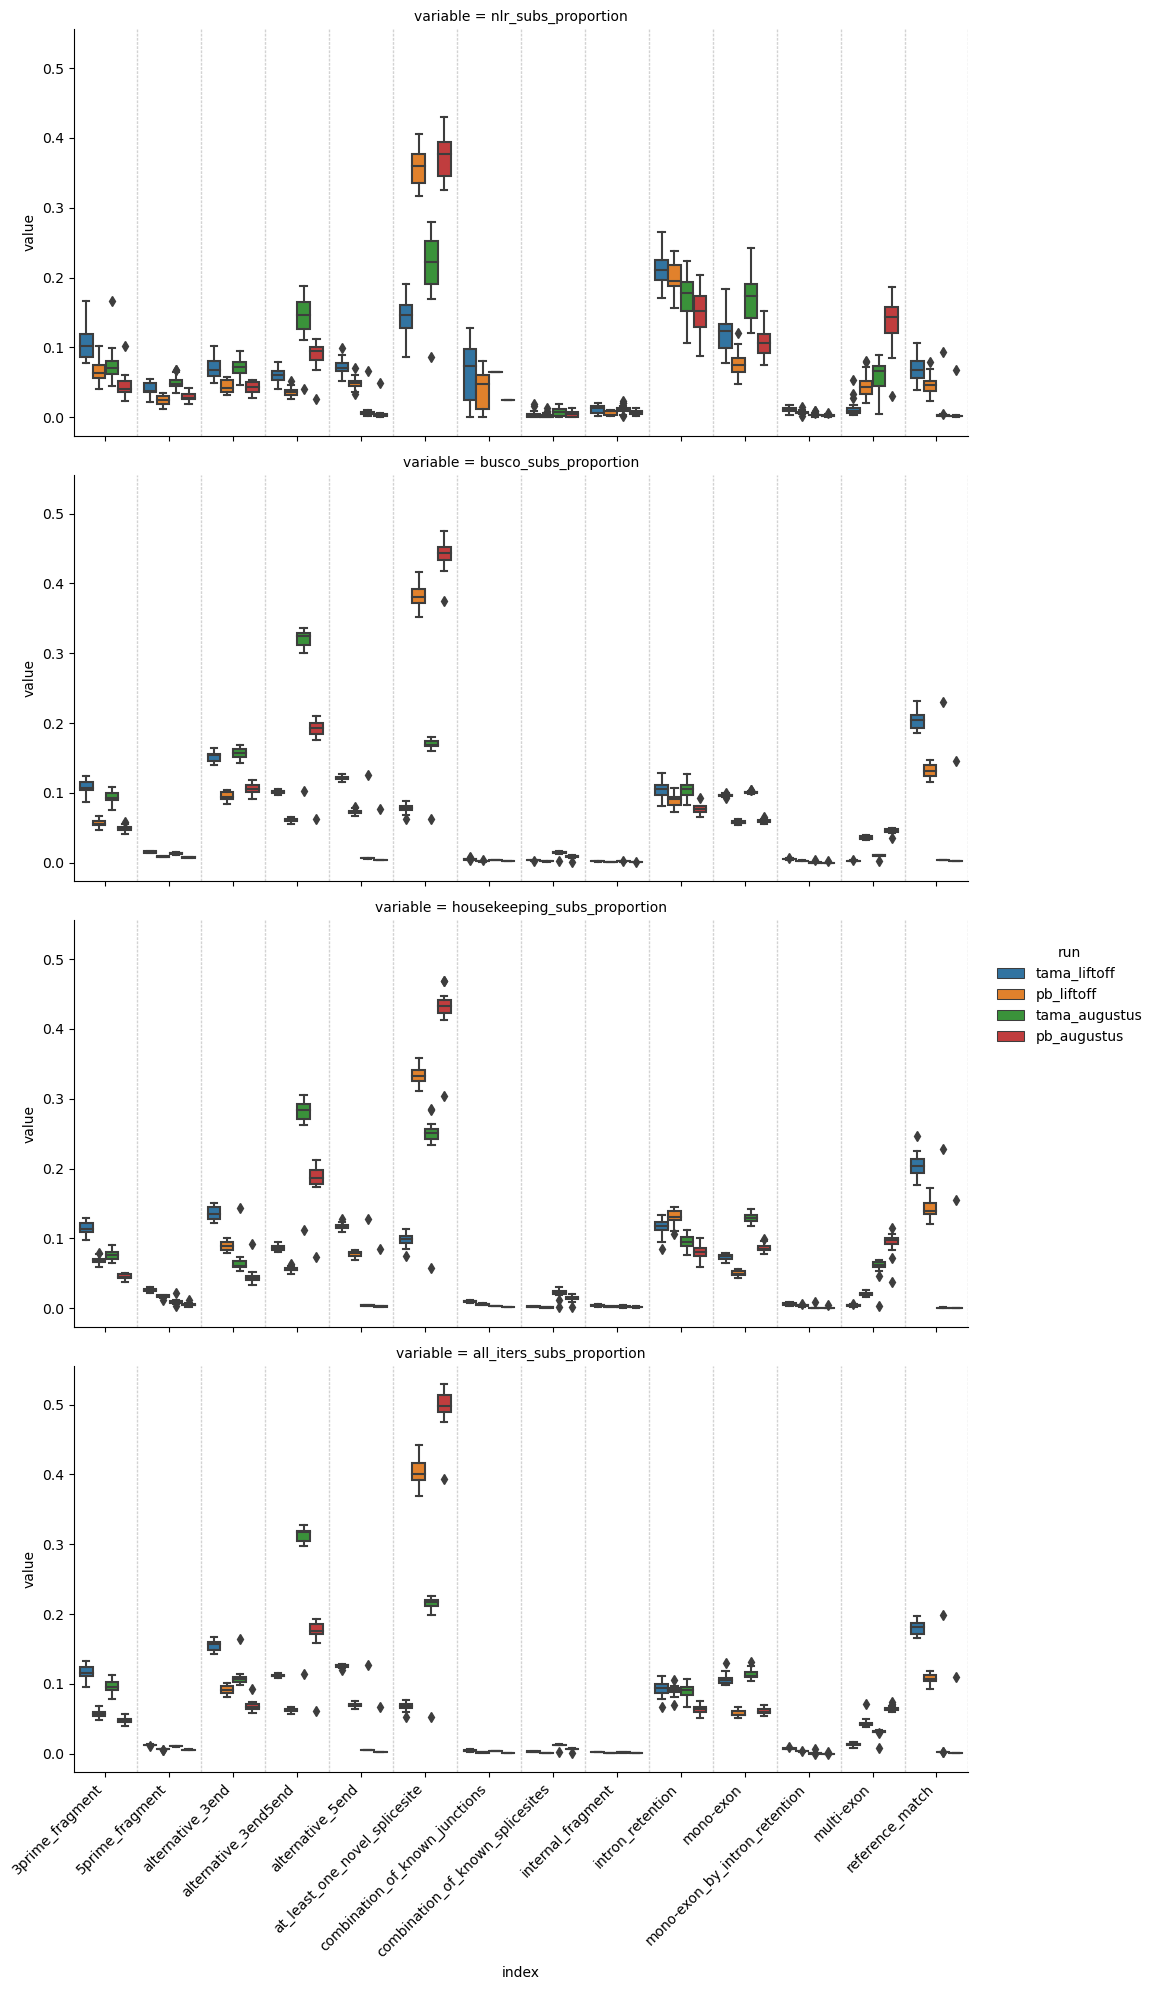

In [6]:
p1=sns.catplot(data=plot1, x="index", y="value", hue="run", col="variable", kind="box", col_wrap=1, aspect=2)
p1.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p1.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

In [ ]:
p1=sns.catplot(data=plot1, x="index", y="value", hue="variable", col="run", kind="box", col_wrap=1, aspect=2)
p1.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p1.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

### 1.2) Sqanti collapsing tool analysis

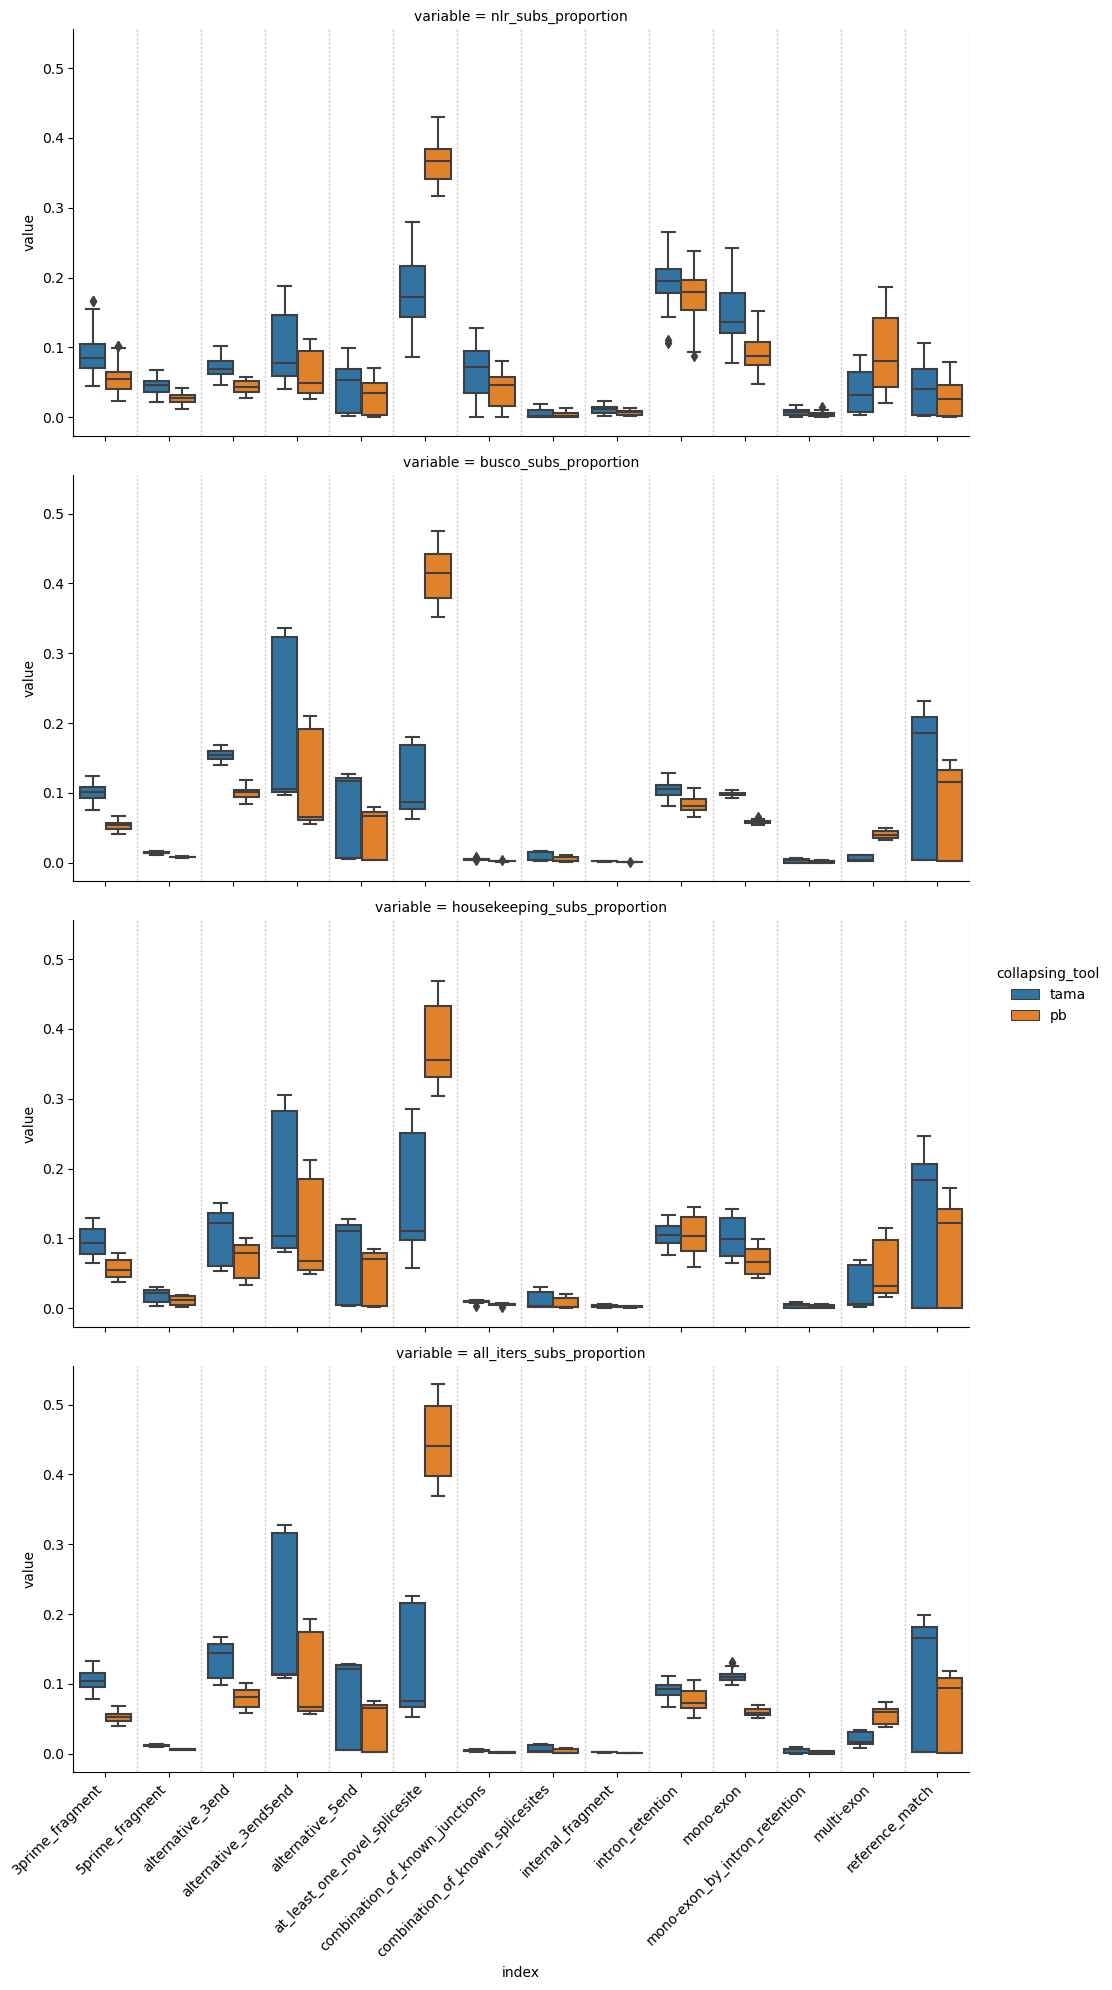

In [16]:
p1_2=sns.catplot(data=plot1, x="index", y="value", hue="collapsing_tool", col="variable", kind="box", col_wrap=1, aspect=2)
p1_2.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p1_2.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

['3prime_fragment', '5prime_fragment', 'alternative_3end', 'alternative_3end5end', 'alternative_5end', 'at_least_one_novel_splicesite', 'combination_of_known_junctions', 'combination_of_known_splicesites', 'internal_fragment', 'intron_retention', 'mono-exon', 'mono-exon_by_intron_retention', 'multi-exon', 'reference_match']


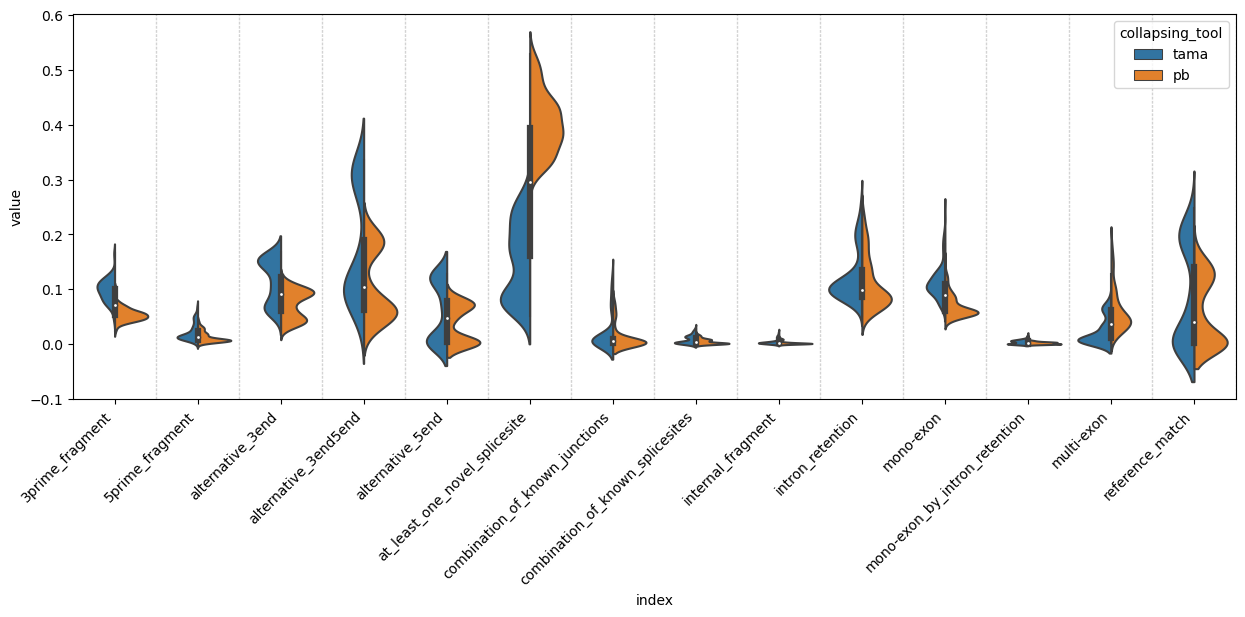

In [36]:
plt.figure(figsize=(15,5))
p1_2_2=sns.violinplot(data=plot1, x="index", y="value", hue="collapsing_tool", split=True)
#p1_2_2.set_xticks()
p1_2_2.set_xticklabels([label.get_text() for label in p1_2_2.get_xticklabels()],rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    plt.axvline( x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

### 1.3) Sqanti prediction tool analysis

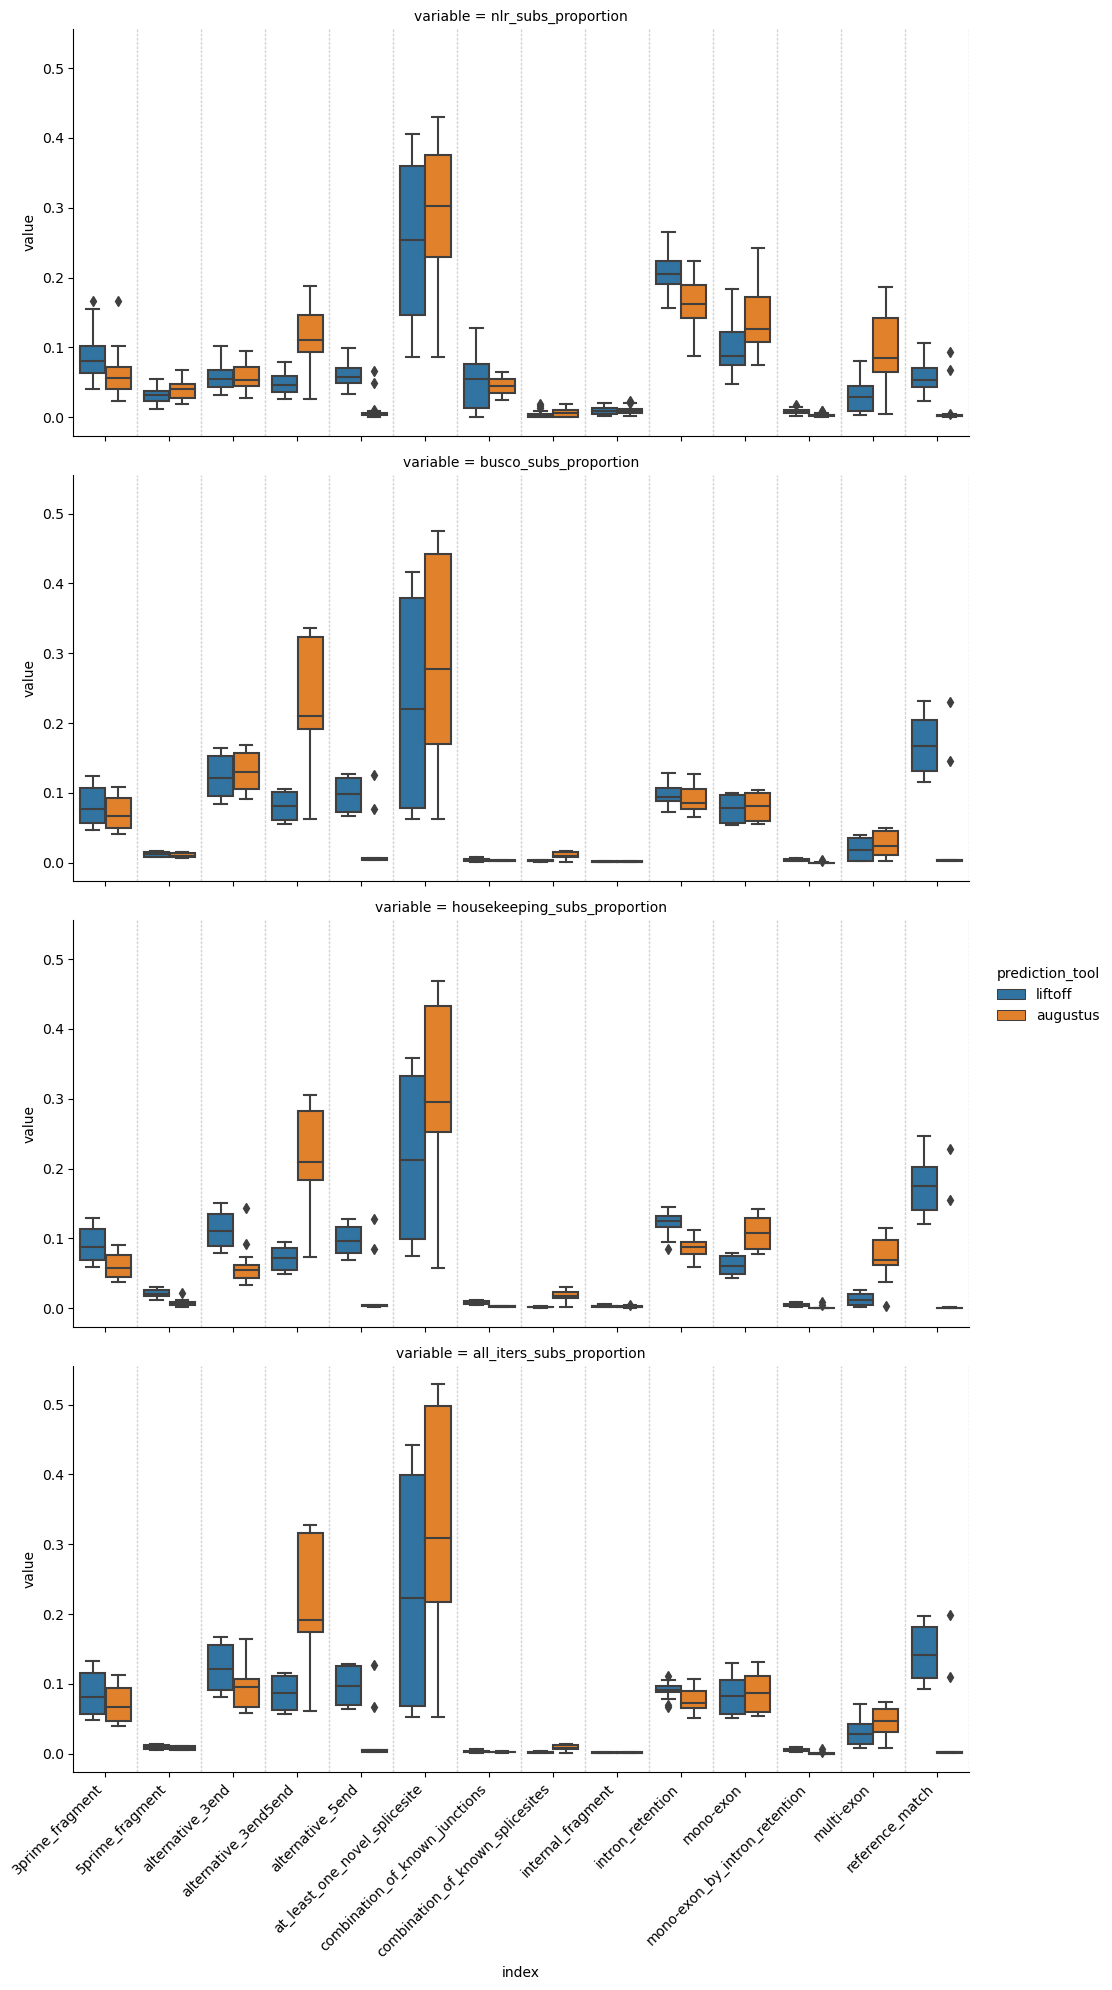

In [8]:
p1_3=sns.catplot(data=plot1, x="index", y="value", hue="prediction_tool", col="variable", kind="box", col_wrap=1, aspect=2)
p1_3.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p1_3.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

['3prime_fragment', '5prime_fragment', 'alternative_3end', 'alternative_3end5end', 'alternative_5end', 'at_least_one_novel_splicesite', 'combination_of_known_junctions', 'combination_of_known_splicesites', 'internal_fragment', 'intron_retention', 'mono-exon', 'mono-exon_by_intron_retention', 'multi-exon', 'reference_match']


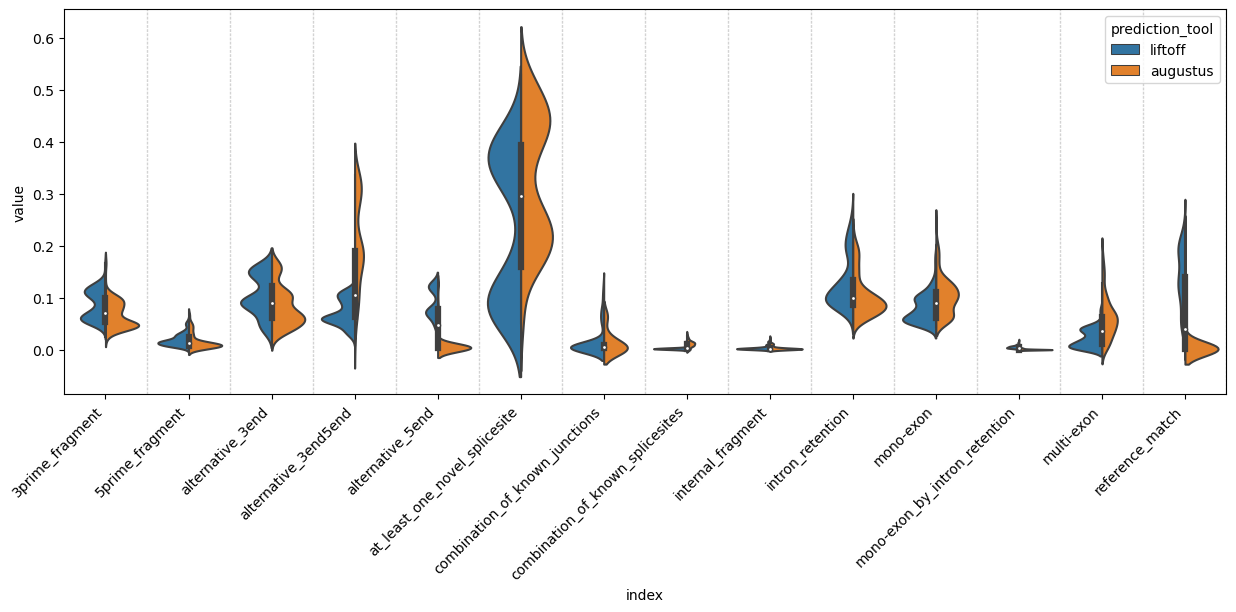

In [38]:
plt.figure(figsize=(15,5))
p1_3_2=sns.violinplot(data=plot1, x="index", y="value", hue="prediction_tool", split=True)
p1_3_2.set_xticklabels([label.get_text() for label in p1_3_2.get_xticklabels()],rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    plt.axvline( x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

### 1.4) Col0 example

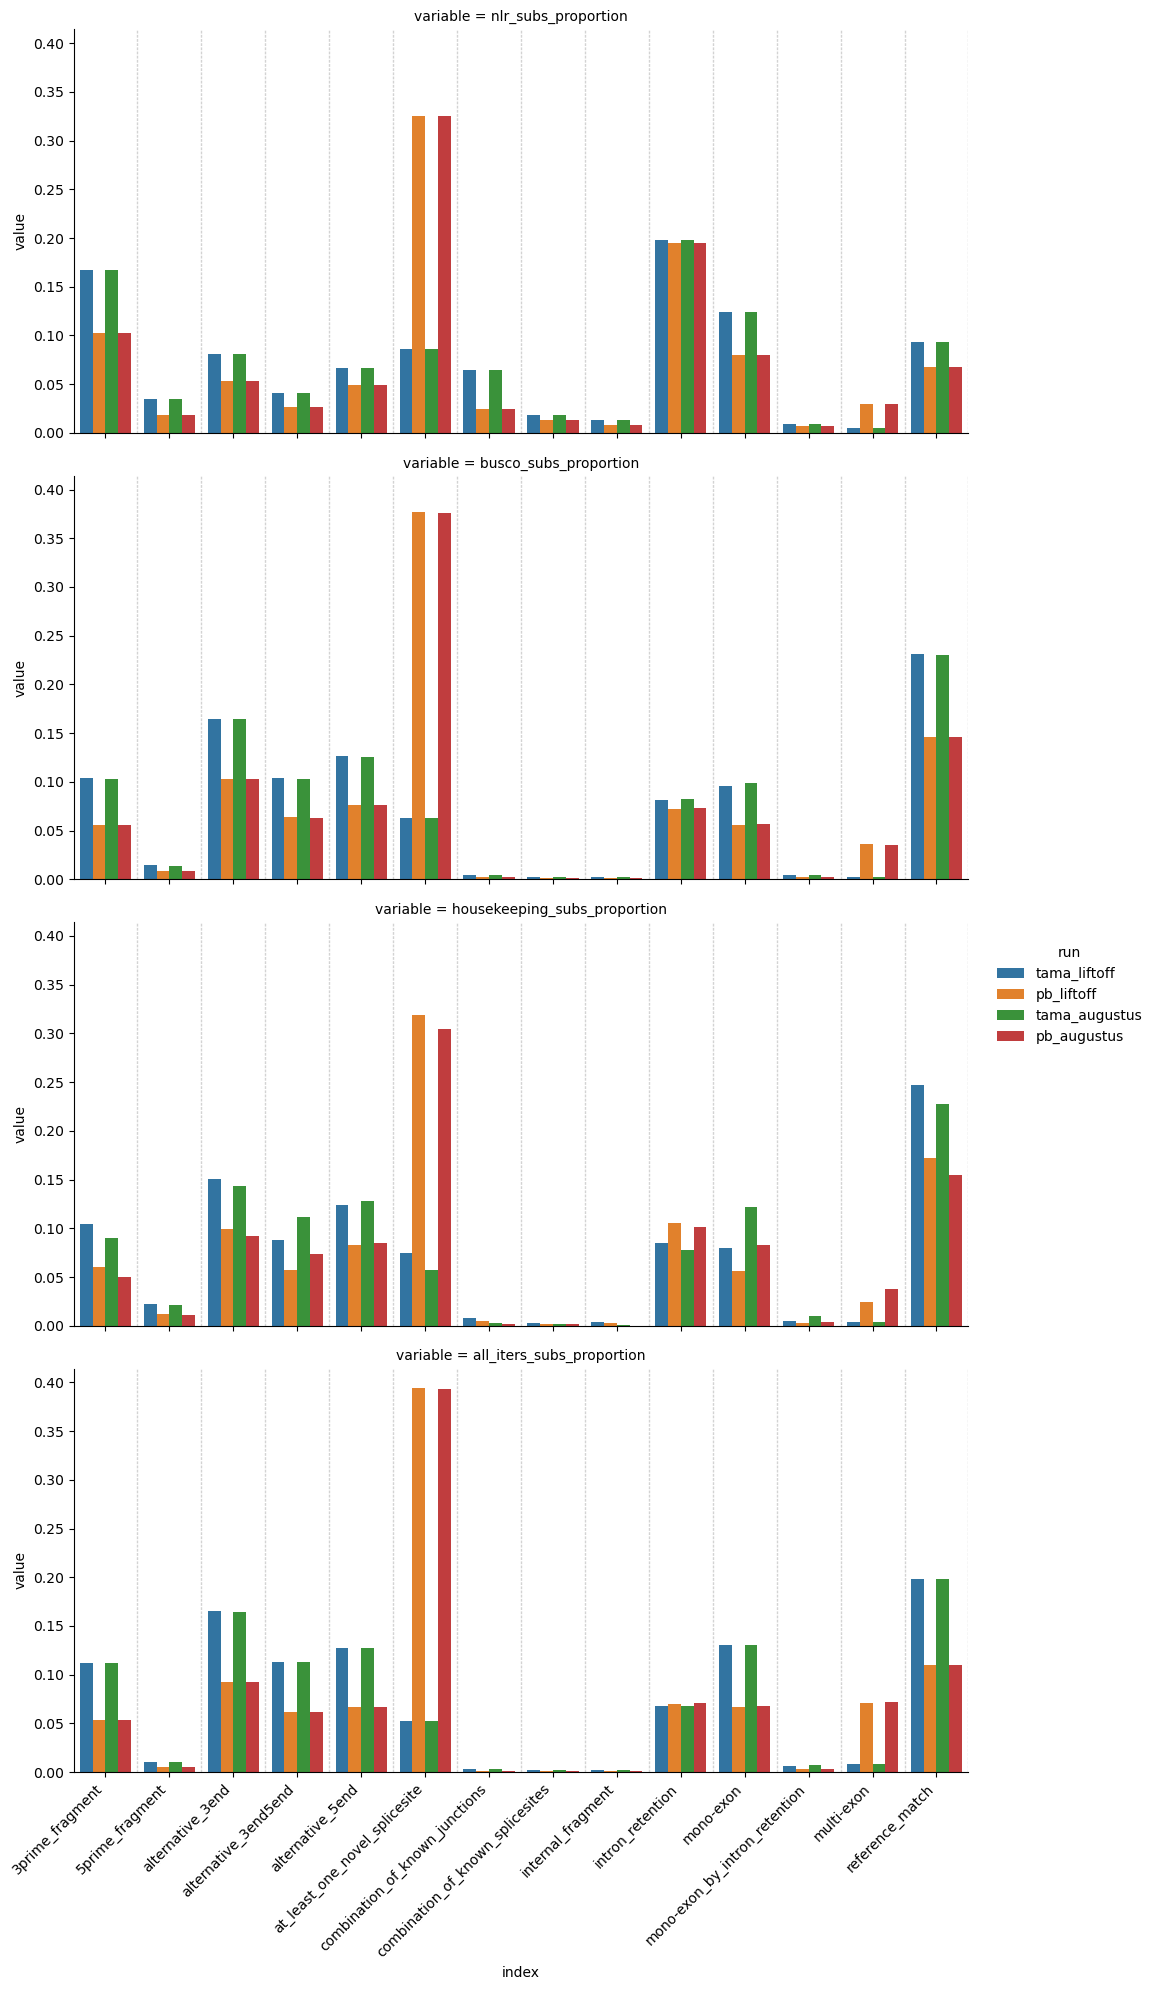

In [25]:
col0_1=plot1.loc[plot1["accession"]=="col0"]
p01=sns.catplot(data=col0_1, x="index", y="value", hue="run", col="variable", kind="bar", col_wrap=1, aspect=2)
p01.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p01.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

## 2) Exon amount

In [81]:
df_subs.head()

,index,nlr_subs,nlr_subs_proportion,busco_iters_subs,busco_iters_subs_proportion,house_iters_subs,house_iters_subs_proportion,all_iters_subs,all_iters_subs_proportion,busco_subs,busco_subs_proportion,housekeeping_subs,housekeeping_subs_proportion,all_subs,all_subs_proportion,accession,run,collapsing_tool,prediction_tool
0,3prime_fragment,443.0,0.125995,402.492,0.114474,422.598,0.120193,438.931,0.124838,6038,0.114464,711.0,0.120305,31133,0.124883,at6923,tama_liftoff,tama,liftoff
1,5prime_fragment,106.0,0.030148,58.219,0.016558,98.773,0.028092,48.429,0.013774,873,0.016550,166.0,0.028088,3405,0.013658,at6923,tama_liftoff,tama,liftoff
2,alternative_3end,195.0,0.055461,498.377,0.141745,464.263,0.132043,512.308,0.145708,7479,0.141782,780.0,0.131980,36285,0.145549,at6923,tama_liftoff,tama,liftoff
3,alternative_3end5end,180.0,0.051195,351.624,0.100007,307.746,0.087527,391.404,0.111321,5276,0.100019,517.0,0.087479,27764,0.111369,at6923,tama_liftoff,tama,liftoff
4,alternative_5end,283.0,0.080489,418.713,0.119088,390.633,0.111102,436.419,0.124124,6293,0.119299,657.0,0.111168,30927,0.124056,at6923,tama_liftoff,tama,liftoff


In [77]:
sqanti_exons=df_exons[["index","accession","run","collapsing_tool","prediction_tool","nlr_exons_proportion","busco_iters_exons_proportion","house_iters_exons_proportion","all_iters_exons_proportion"]]

In [78]:
plot2=sqanti_exons.melt(id_vars=["index","accession","run","collapsing_tool","prediction_tool"], value_vars=["nlr_exons_proportion","busco_iters_exons_proportion","house_iters_exons_proportion","all_iters_exons_proportion"])

In [79]:
plot2.head()

,index,accession,run,collapsing_tool,prediction_tool,variable,value
0,1,at6923,tama_liftoff,tama,liftoff,nlr_exons_proportion,0.087884
1,2,at6923,tama_liftoff,tama,liftoff,nlr_exons_proportion,0.128840
2,3,at6923,tama_liftoff,tama,liftoff,nlr_exons_proportion,0.093572
3,4,at6923,tama_liftoff,tama,liftoff,nlr_exons_proportion,0.129693
4,5,at6923,tama_liftoff,tama,liftoff,nlr_exons_proportion,0.131399


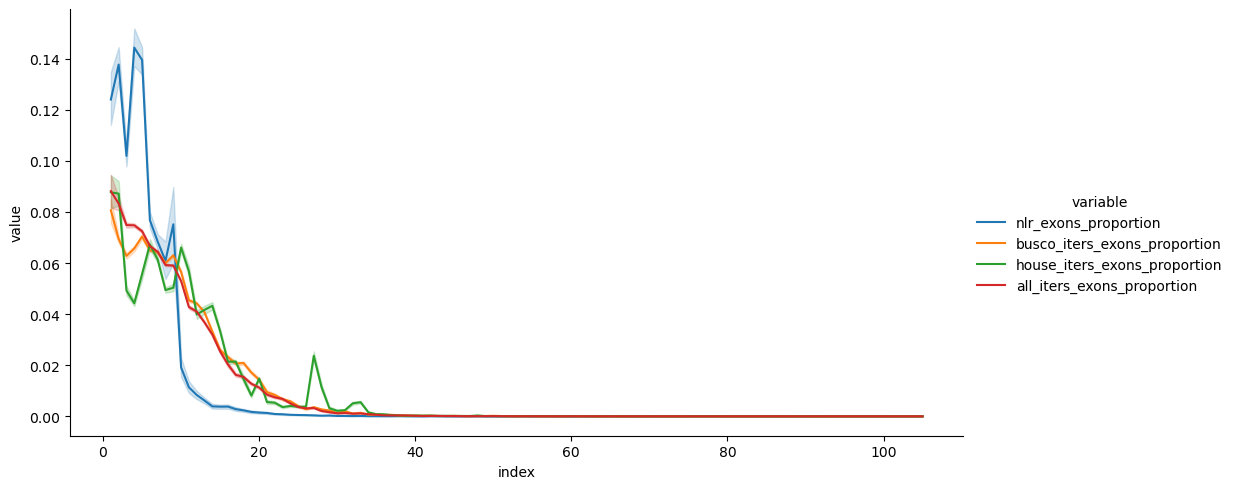

In [80]:
p2=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", aspect=2)

### Exon amount over all collapsing runs

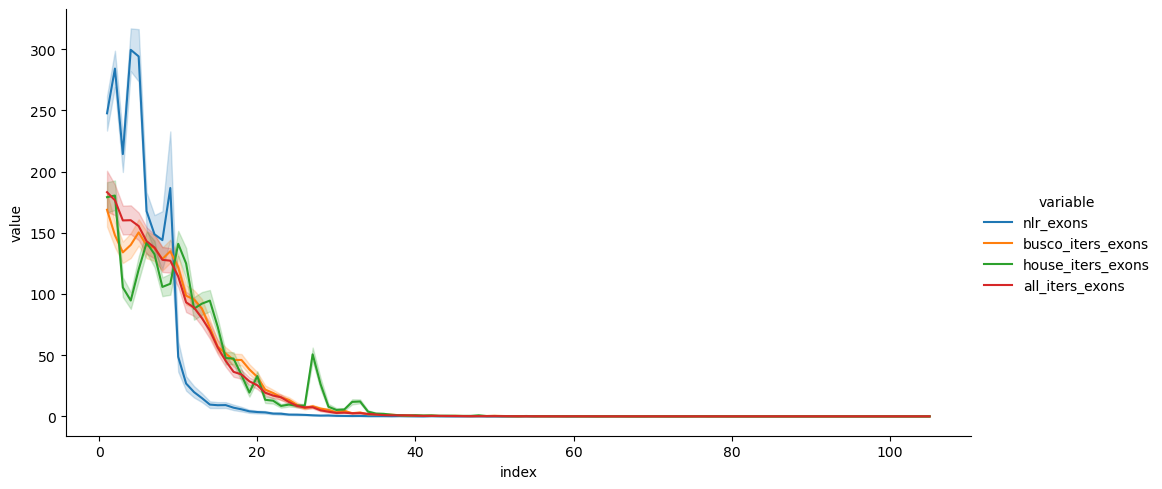

In [14]:
p2=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", aspect=2)

### Exon amount over all collapsing runs (separated by run)

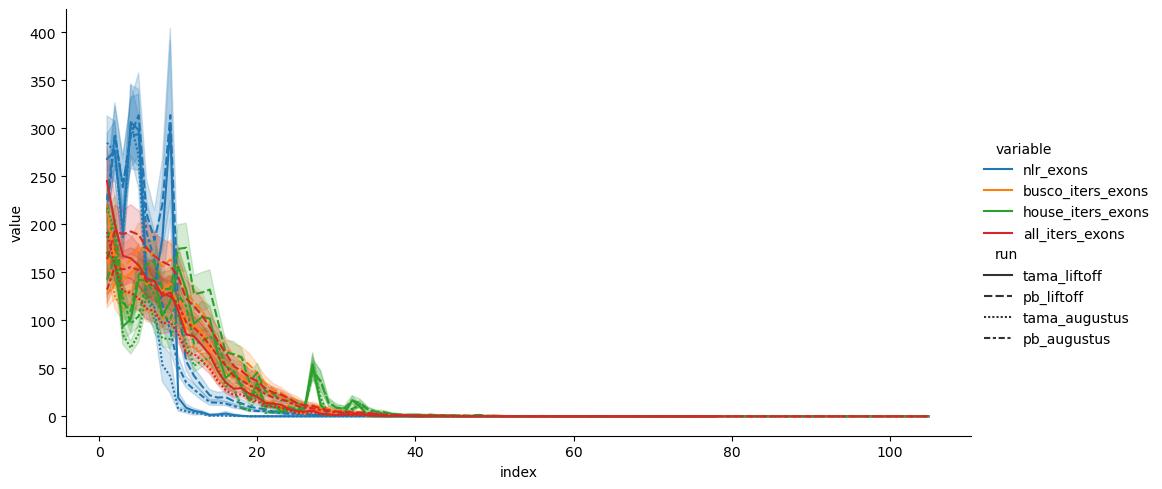

In [15]:
p2_2=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", style="run" ,aspect=2)

### Exon amount over all collapsing runs (separated by collapsing tool)

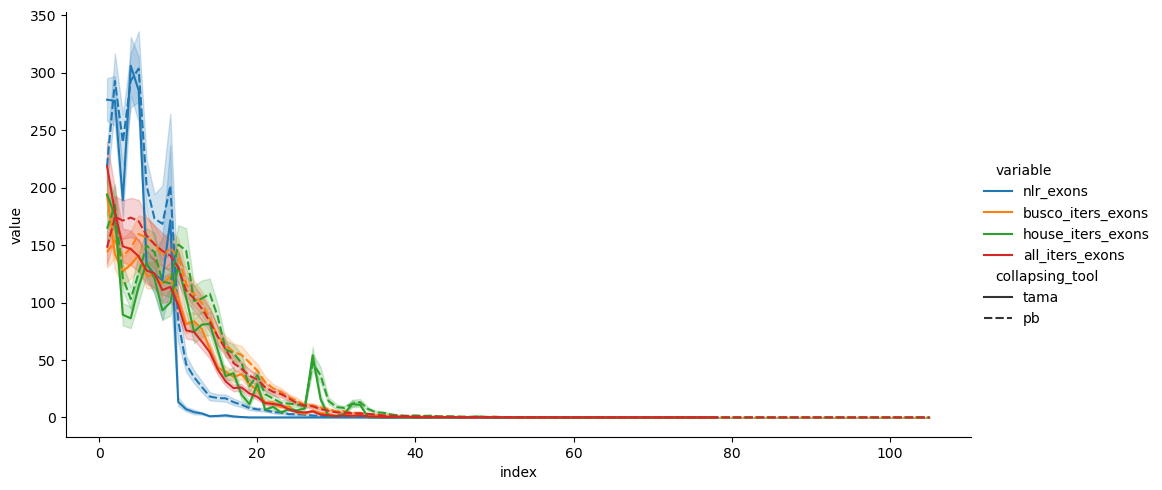

In [16]:
#sqanti_exons_ctool=df_exons[["index","accession","run","nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"]].copy()
#sqanti_exons_ctool["collapsing_tool"] = sqanti_exons_ctool["run"].str.split("_").str[0]
#plot2_2=sqanti_exons_ctool.melt(id_vars=["index","accession","run","collapsing_tool"], value_vars=["nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"])
p2_3=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", style="collapsing_tool",aspect=2)

### Exon amount over all collapsing runs (separated by updated prediction)

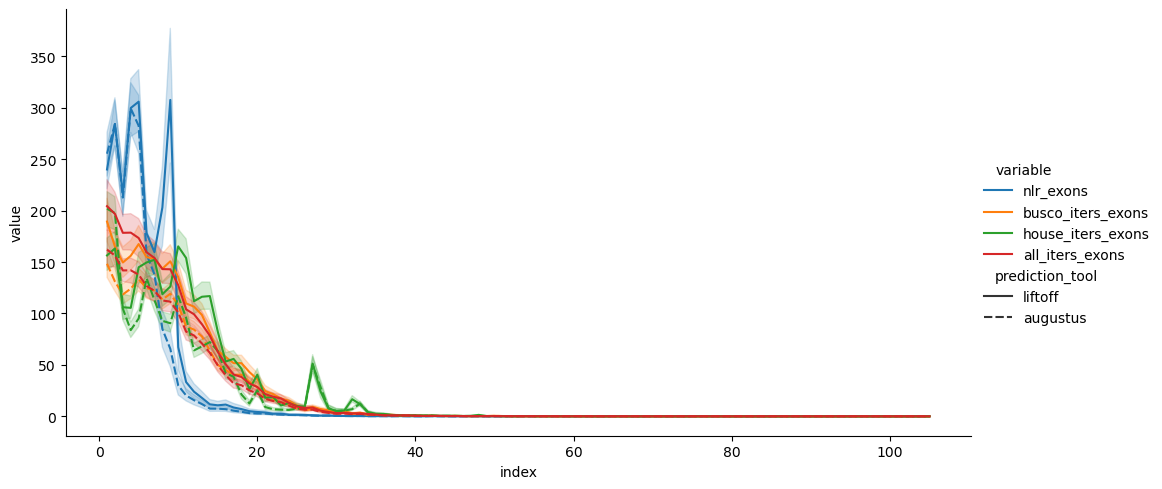

In [17]:
#sqanti_exons_ctool=df_exons[["index","accession","run","nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"]].copy()
#sqanti_exons_ctool["prediction_tool"] = sqanti_exons_ctool["run"].str.split("_").str[1]
#plot2_3=sqanti_exons_ctool.melt(id_vars=["index","accession","run","prediction_tool"], value_vars=["nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"])
p2_4=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", style="prediction_tool",aspect=2)

### Exon amount per collapsing run

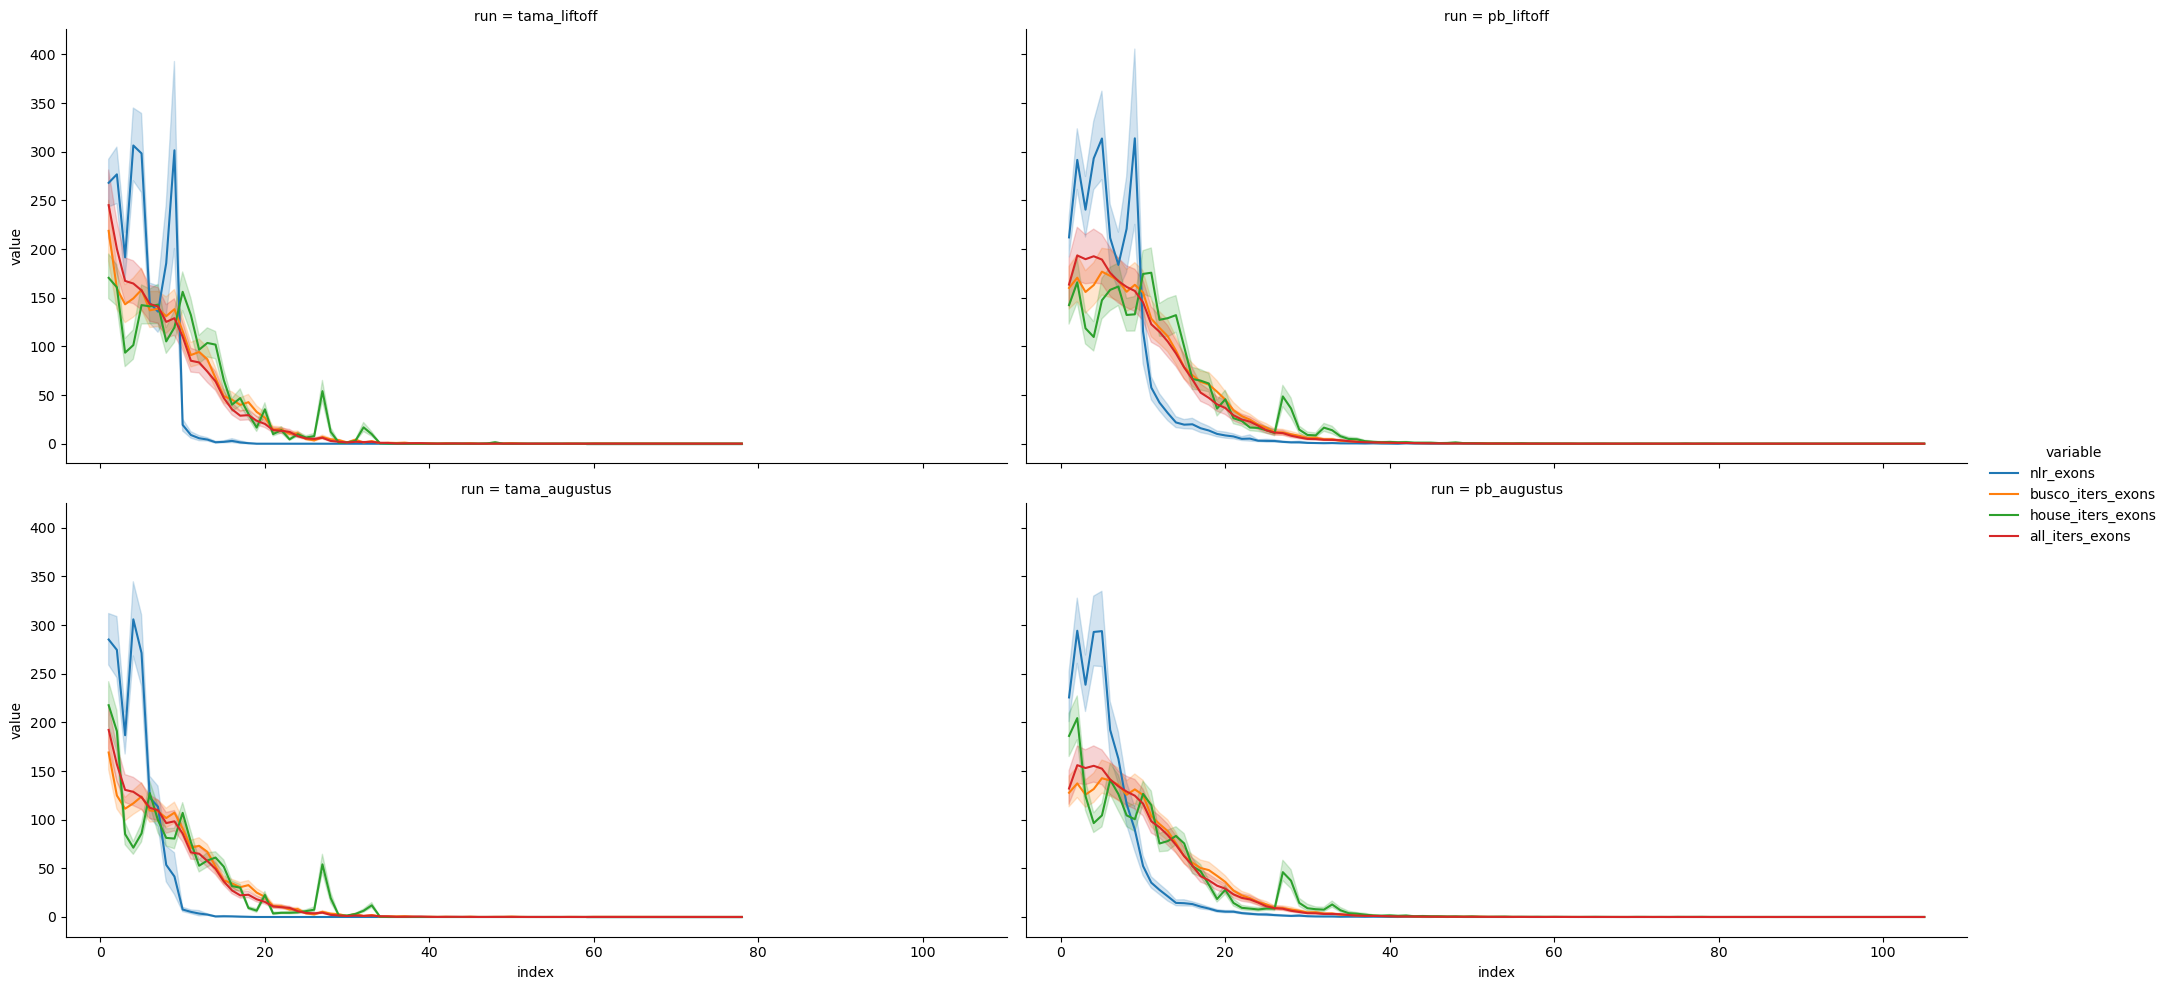

In [18]:
p2_5=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", col="run", col_wrap=2,aspect=2)

### Col0 example

In [19]:
col0_2=plot2.loc[plot2["accession"]=="col0"]

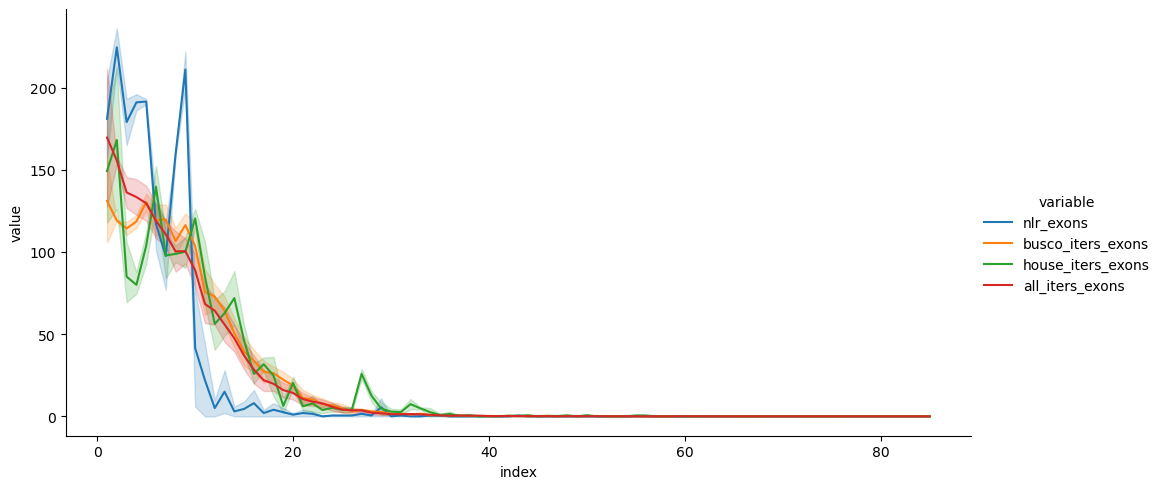

In [20]:
### Exon amount over all collapsing runs
c02=sns.relplot(data=col0_2, x="index", y="value", hue="variable", kind="line", aspect=2)

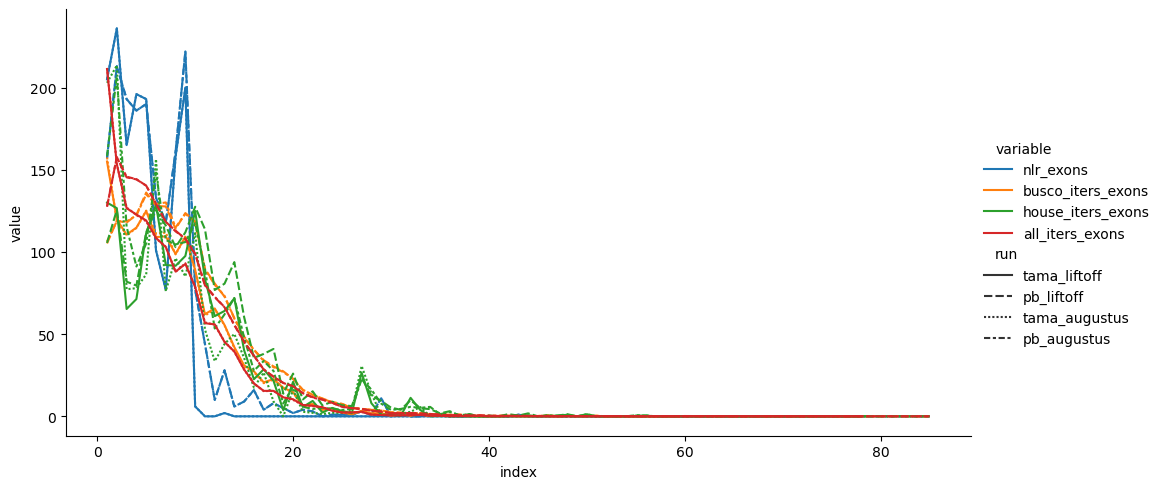

In [21]:
### Exon amount over all collapsing runs (separated by run)
c02_2=sns.relplot(data=col0_2, x="index", y="value", hue="variable", kind="line", style="run" ,aspect=2)

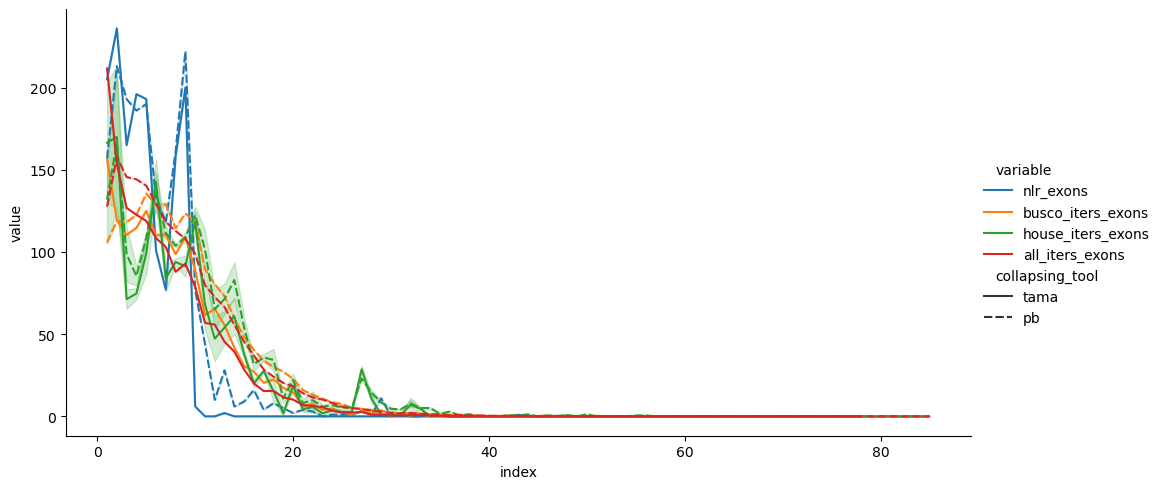

In [22]:
### Exon amount over all collapsing runs (separated by collapsing tool)
c02_3=sns.relplot(data=col0_2, x="index", y="value", hue="variable", kind="line", style="collapsing_tool",aspect=2)

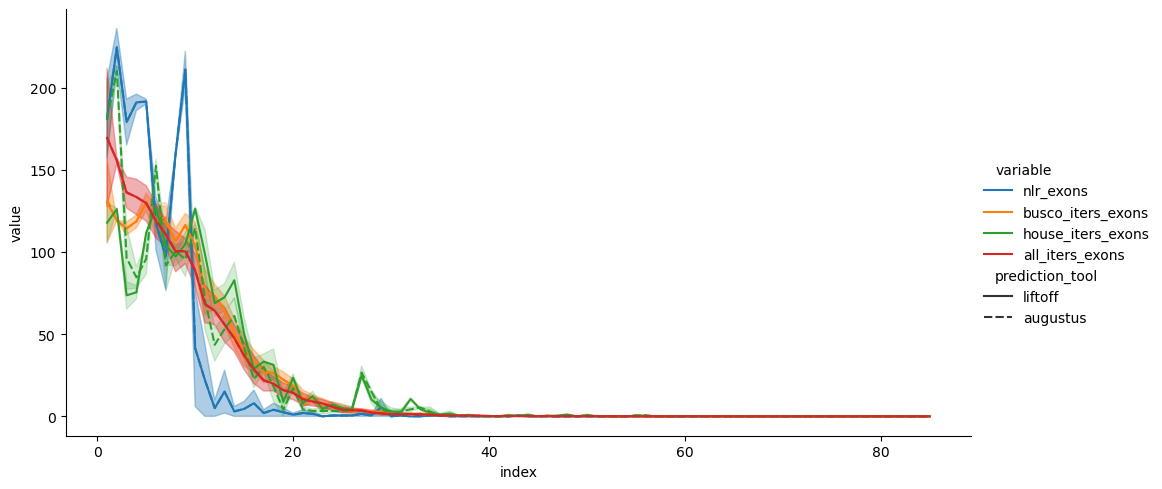

In [23]:
### Exon amount over all collapsing runs (separated by updated prediction)
c02_4=sns.relplot(data=col0_2, x="index", y="value", hue="variable", kind="line", style="prediction_tool",aspect=2)

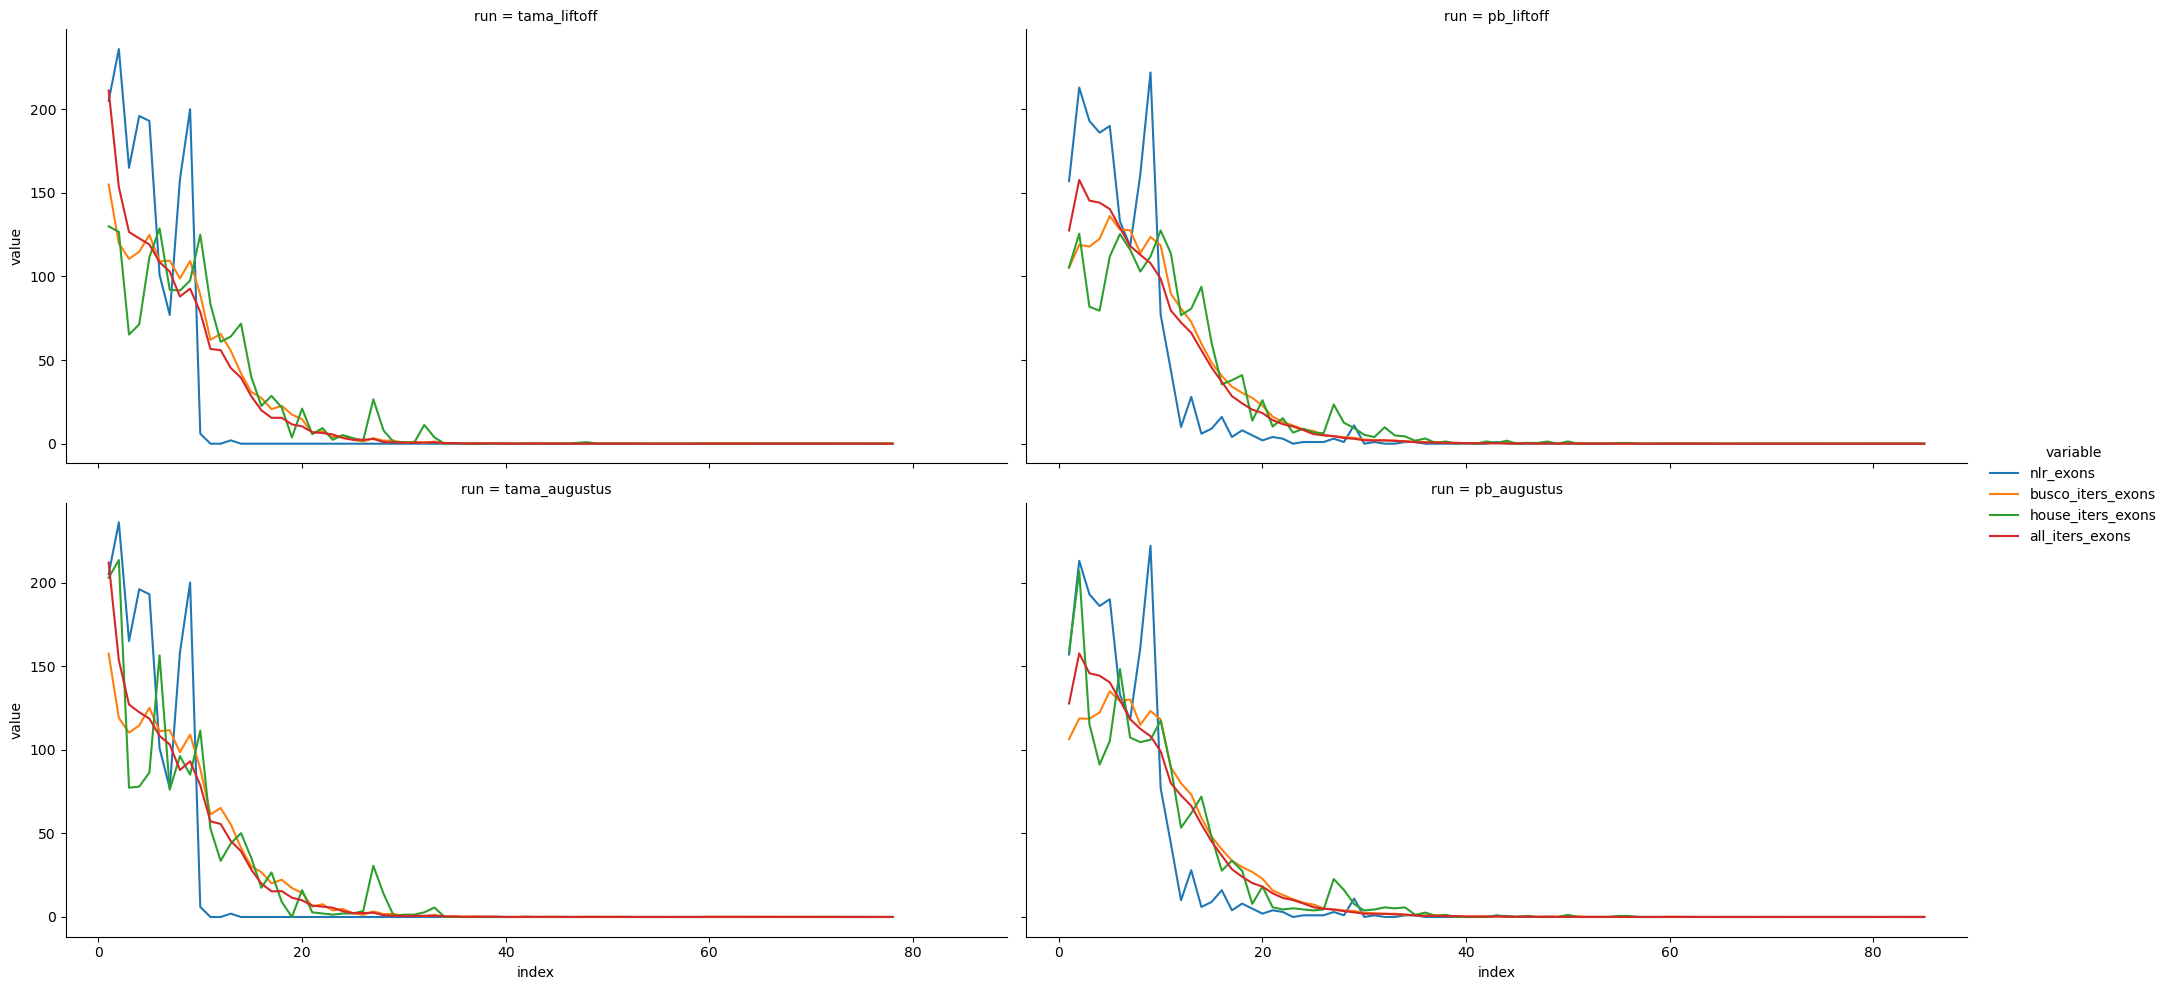

In [24]:
### Exon amount per collapsing run (diplicated annotations for the two annotation tools...)
c02_5=sns.relplot(data=col0_2, x="index", y="value", hue="variable", kind="line", col="run", col_wrap=2,aspect=2)

## 1.3) Length distributions

In [26]:
sqanti_length=df_length[["index","accession","run","collapsing_tool","prediction_tool","nlr_length","busco_iters_length","house_iters_length","all_iters_length"]]

In [27]:
plot3=sqanti_length.melt(id_vars=["index","accession","run","collapsing_tool","prediction_tool"], value_vars=["nlr_length","busco_iters_length","house_iters_length","all_iters_length"])

In [28]:
plot3.head()

,index,accession,run,collapsing_tool,prediction_tool,variable,value
0,119,at6923,tama_liftoff,tama,liftoff,nlr_length,0.0
1,127,at6923,tama_liftoff,tama,liftoff,nlr_length,0.0
2,145,at6923,tama_liftoff,tama,liftoff,nlr_length,0.0
3,147,at6923,tama_liftoff,tama,liftoff,nlr_length,0.0
4,150,at6923,tama_liftoff,tama,liftoff,nlr_length,0.0


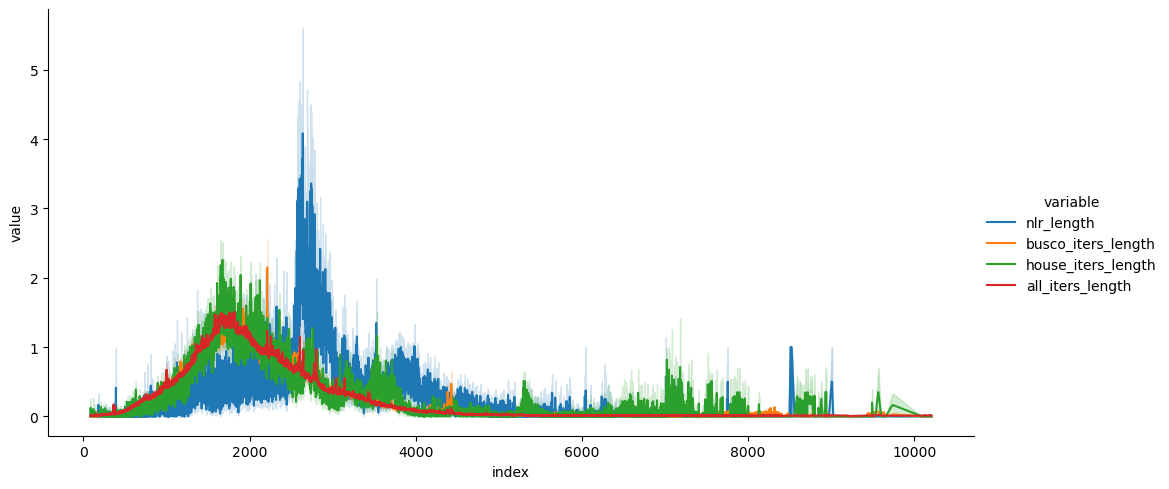

In [29]:
p3=sns.relplot(data=plot3, x="index", y="value", hue="variable", kind="line", aspect=2)

## 1.3) Length distributions (rolling mean)

In [30]:
sqanti_length_rolling_mean=df_length[["index","accession","run","collapsing_tool","prediction_tool","nlr_length","busco_iters_length","house_iters_length","all_iters_length"]].sort_values("index")

In [31]:
rolling_means=pd.DataFrame()
for acc in sqanti_length_rolling_mean["accession"].unique().tolist():
    acc_means=pd.DataFrame()
    acc_df = sqanti_length_rolling_mean.loc[sqanti_length_rolling_mean["accession"]==acc].copy()
    for run in acc_df["run"].unique().tolist():
        run_df=acc_df.loc[acc_df["run"] == run].copy()
        run_df['nlr_length_rolling10'] = run_df['nlr_length'].rolling(10).mean()
        run_df['busco_iters_length_rolling10'] = run_df['busco_iters_length'].rolling(10).mean()
        run_df['house_iters_length_rolling10'] = run_df['house_iters_length'].rolling(10).mean()
        run_df['all_iters_length_rolling10'] = run_df['all_iters_length'].rolling(10).mean()
        acc_means=pd.concat([acc_means, run_df])
    rolling_means=pd.concat([rolling_means, acc_means])
rolling_means=rolling_means[["index","accession","run","collapsing_tool","prediction_tool","nlr_length_rolling10","busco_iters_length_rolling10","house_iters_length_rolling10","all_iters_length_rolling10"]]

In [32]:
plot3_2=rolling_means.melt(id_vars=["index","accession","run","collapsing_tool","prediction_tool"], value_vars=["nlr_length_rolling10","busco_iters_length_rolling10","house_iters_length_rolling10","all_iters_length_rolling10"]).fillna(0)

In [33]:
plot3_2.head()

,index,accession,run,collapsing_tool,prediction_tool,variable,value
0,81,at9336,pb_augustus,pb,augustus,nlr_length_rolling10,0.0
1,101,at9336,pb_augustus,pb,augustus,nlr_length_rolling10,0.0
2,114,at9336,pb_augustus,pb,augustus,nlr_length_rolling10,0.0
3,122,at9336,pb_augustus,pb,augustus,nlr_length_rolling10,0.0
4,127,at9336,pb_augustus,pb,augustus,nlr_length_rolling10,0.0


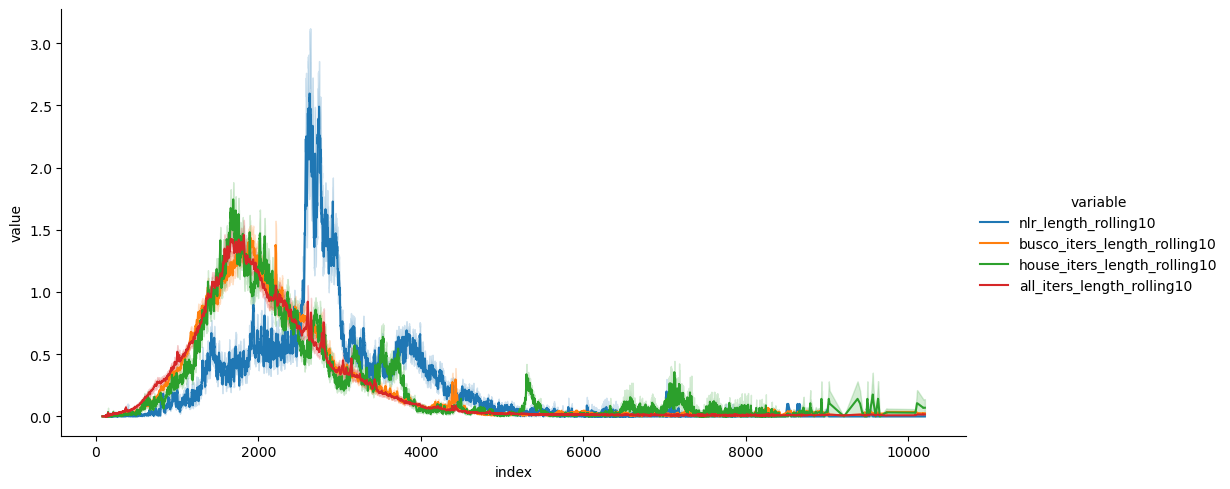

In [34]:
p3_2=sns.relplot(data=plot3_2, x="index", y="value", hue="variable", kind="line", aspect=2)

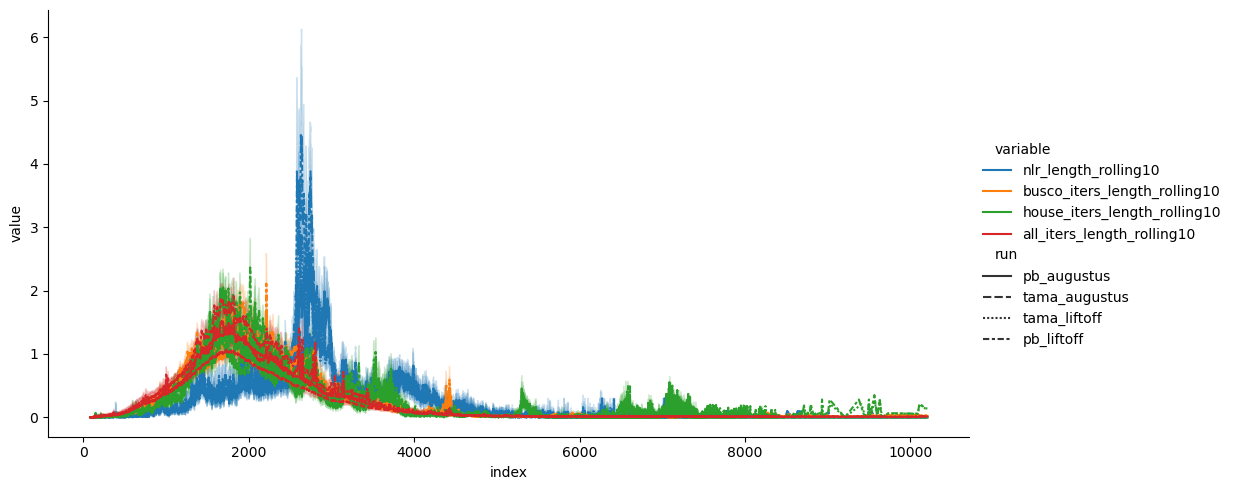

In [35]:
p3_3=sns.relplot(data=plot3_2, x="index", y="value", hue="variable", kind="line", style="run", aspect=2)

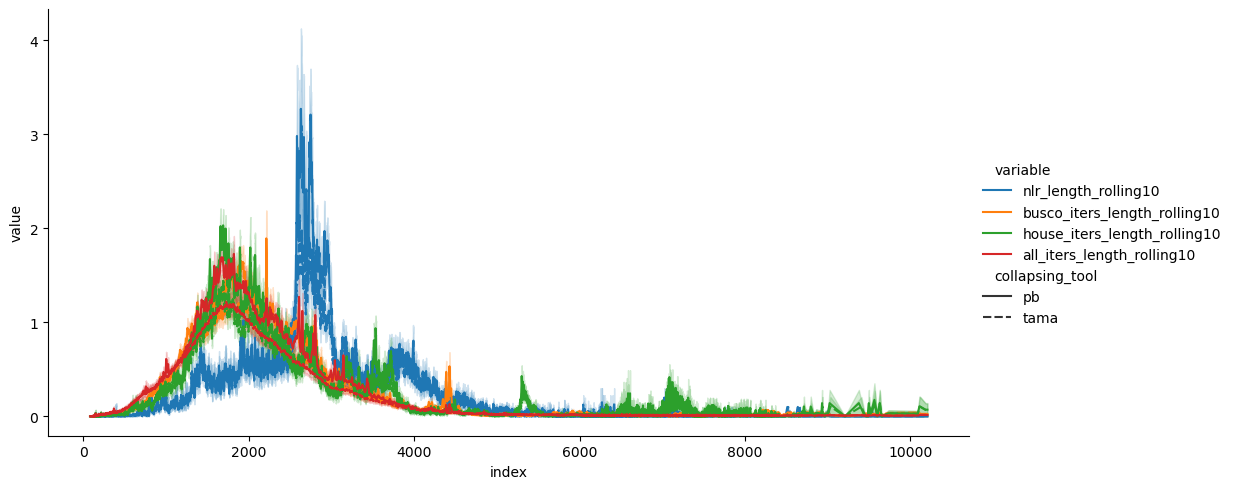

In [36]:
p3_4=sns.relplot(data=plot3_2, x="index", y="value", hue="variable", kind="line", style="collapsing_tool", aspect=2)

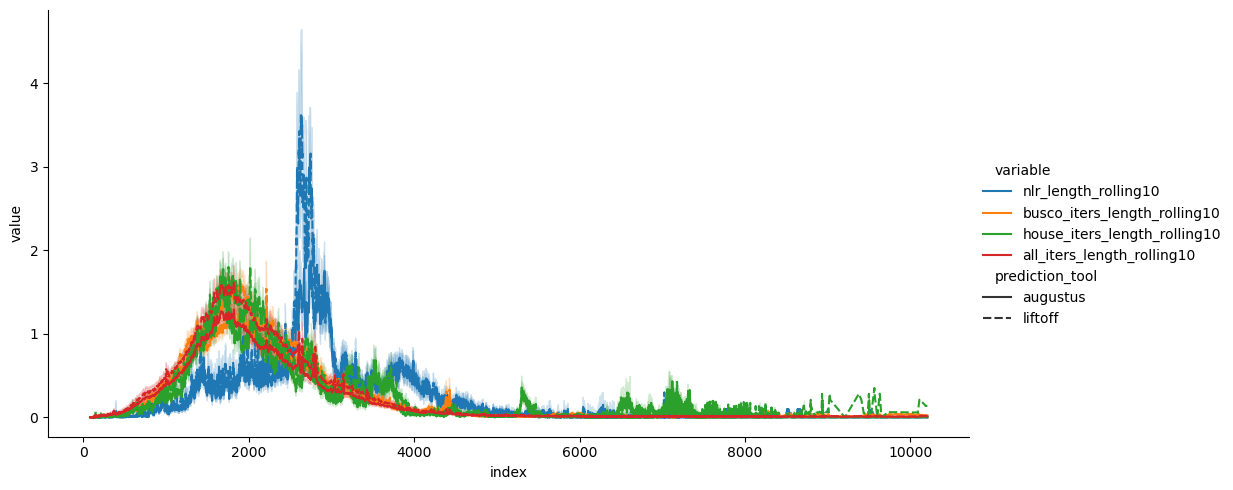

In [37]:
p3_4=sns.relplot(data=plot3_2, x="index", y="value", hue="variable", kind="line", style="prediction_tool", aspect=2)

In [39]:
#p3_5=sns.relplot(data=plot3_2, x="index", y="value", hue="variable", kind="line", col="run", col_wrap=2, aspect=2)

### Col0 example

In [40]:
col0_3=plot3_2.loc[plot3_2["accession"]=="col0"]

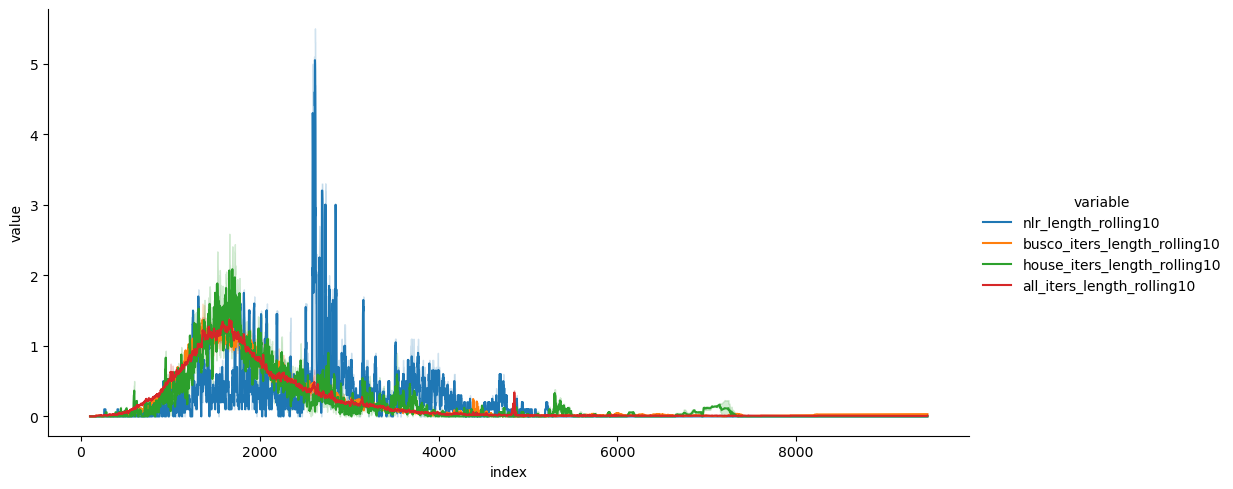

In [41]:
### Exon amount over all collapsing runs
c03=sns.relplot(data=col0_3, x="index", y="value", hue="variable", kind="line", aspect=2)

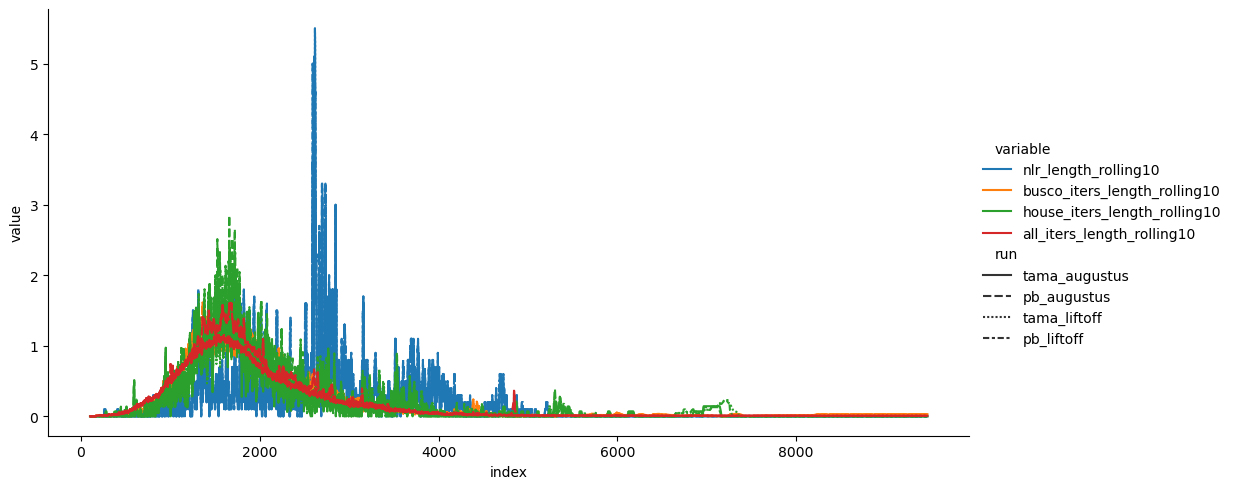

In [42]:
### Exon amount over all collapsing runs (separated by run)
c03_2=sns.relplot(data=col0_3, x="index", y="value", hue="variable", kind="line", style="run" ,aspect=2)

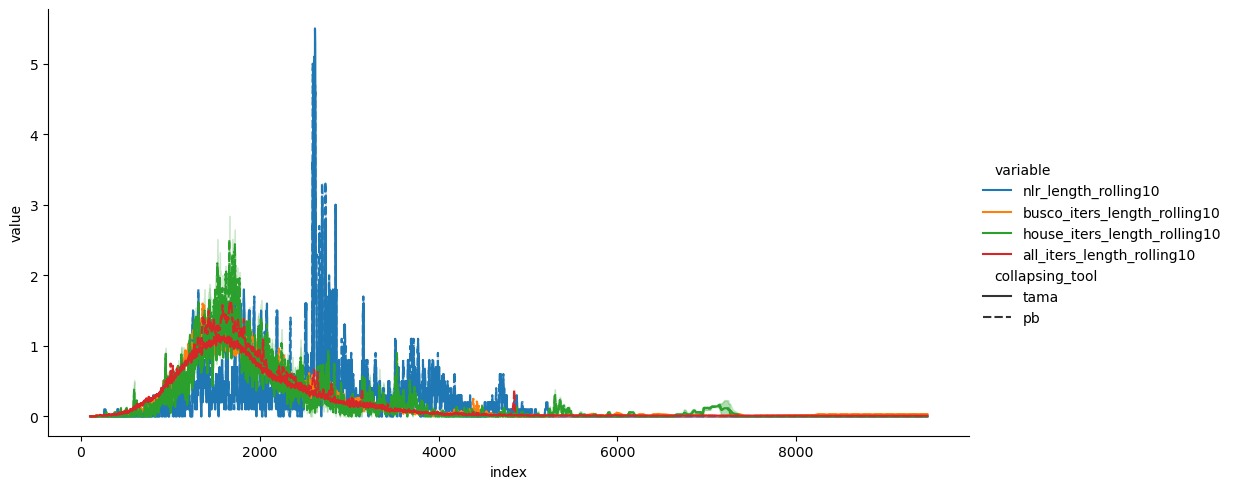

In [43]:
### Exon amount over all collapsing runs (separated by collapsing tool)
c03_3=sns.relplot(data=col0_3, x="index", y="value", hue="variable", kind="line", style="collapsing_tool",aspect=2)

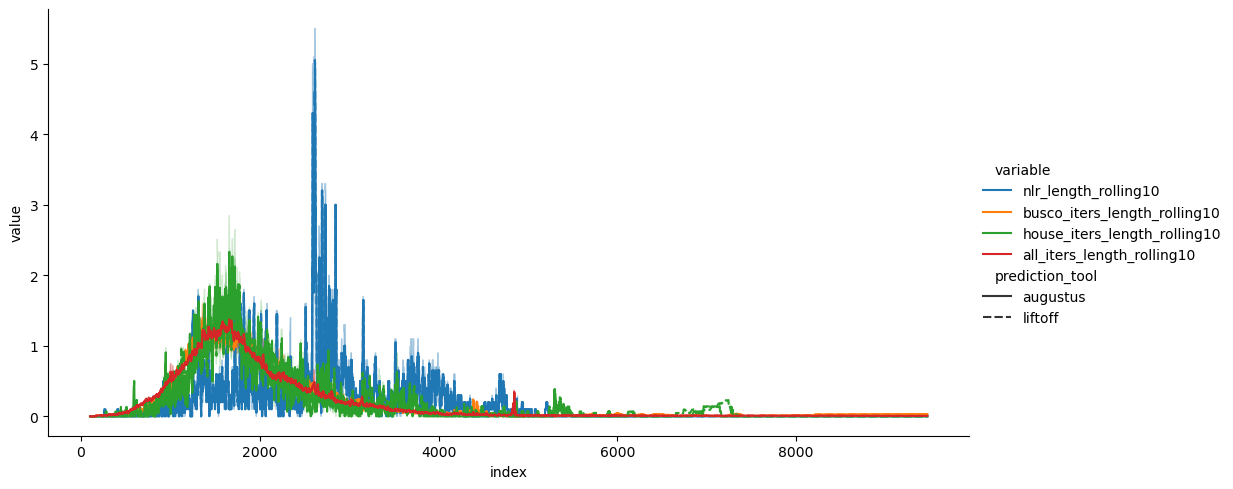

In [44]:
### Exon amount over all collapsing runs (separated by updated prediction)
c03_4=sns.relplot(data=col0_3, x="index", y="value", hue="variable", kind="line", style="prediction_tool",aspect=2)

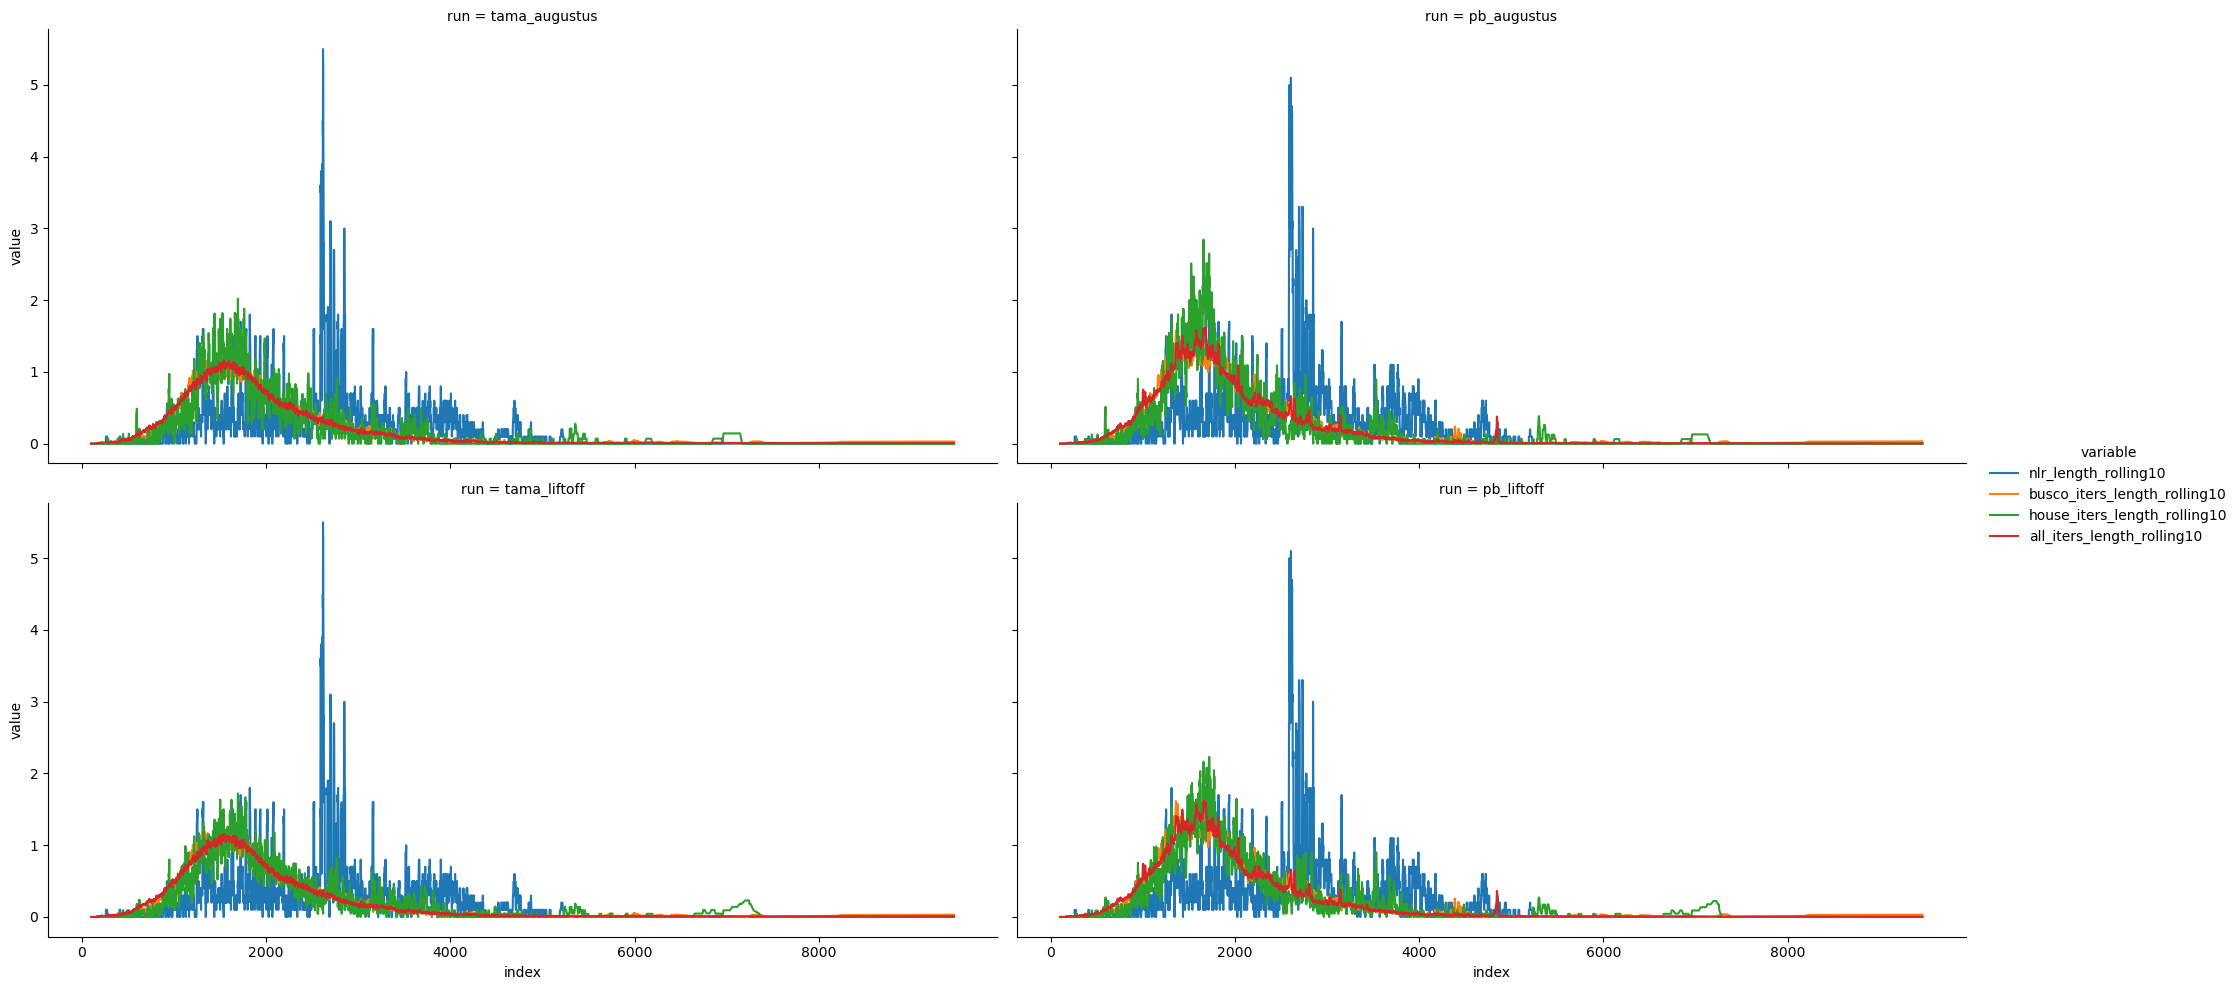

In [45]:
### Exon amount per collapsing run (diplicated annotations for the two annotation tools...)
c03_5=sns.relplot(data=col0_3, x="index", y="value", hue="variable", kind="line", col="run", col_wrap=2,aspect=2)

----

# Section 2: Tama + Augustus

In [40]:
tama_aug_subs = df_subs.loc[df_subs["run"]=="tama_augustus"]
tama_aug_exons = df_exons.loc[df_exons["run"]=="tama_augustus"]
tama_aug_length = df_length.loc[df_length["run"]=="tama_augustus"]

## 2.1) Sqanti subsections

In [41]:
sqanti_subs=tama_aug_subs[["index","accession","run","nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"]]

In [42]:
plot1=sqanti_subs.melt(id_vars=["index","accession","run"], value_vars=["nlr_subs_proportion","busco_subs_proportion","housekeeping_subs_proportion","all_iters_subs_proportion"])

In [43]:
plot1.head()

,index,accession,run,variable,value
0,3prime_fragment,at6923,tama_augustus,nlr_subs_proportion,0.071006
1,5prime_fragment,at6923,tama_augustus,nlr_subs_proportion,0.035503
2,alternative_3end,at6923,tama_augustus,nlr_subs_proportion,0.074810
3,alternative_3end5end,at6923,tama_augustus,nlr_subs_proportion,0.187658
4,alternative_5end,at6923,tama_augustus,nlr_subs_proportion,0.008030


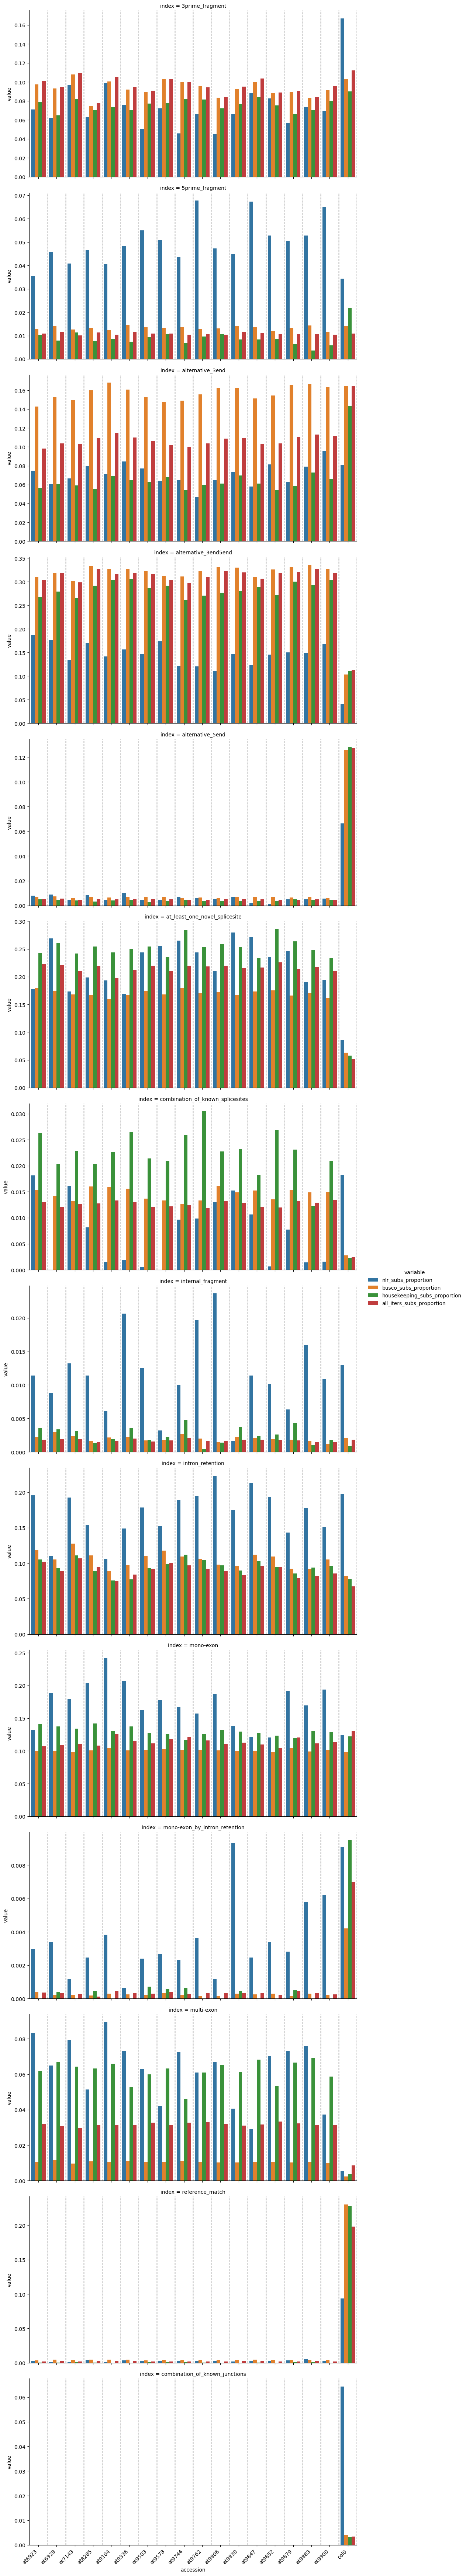

In [44]:
p1=sns.catplot(data=plot1, x="accession", y="value", hue="variable", col="index", kind="bar", col_wrap=1, aspect=2, sharey=False)
p1.set_xticklabels(rotation=45, horizontalalignment='right')

# adding lines in general: https://community.dataquest.io/t/i-want-to-add-vertical-lines-in-a-sns-facetgrid-how-can-i-do-that/546424/2
for i in range(len(plot1["accession"].unique().tolist())):
    p1.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=2)

#import numpy as np
#for ax in p1.axes.flat:
#    ax.grid(True, axis='x', )
#    ax.set_xticks(np.arange(0,len(plot1["accession"].unique().tolist()))-0.5)

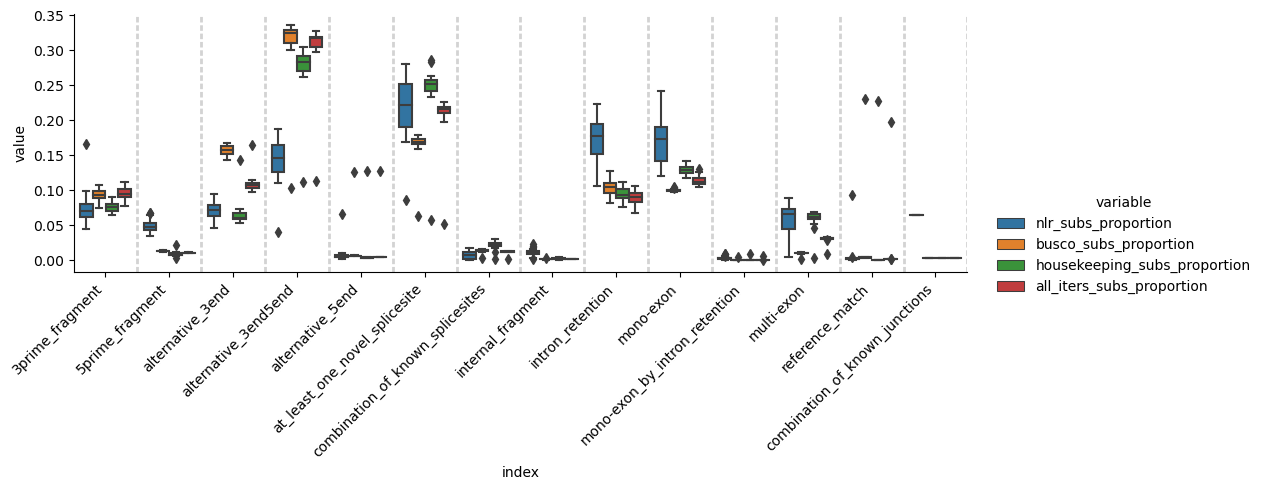

In [167]:
p1_1=sns.catplot(data=plot1, x="index", y="value", hue="variable", kind="box", aspect=2)
p1_1.set_xticklabels(rotation=45, horizontalalignment='right')

# adding lines in general: https://community.dataquest.io/t/i-want-to-add-vertical-lines-in-a-sns-facetgrid-how-can-i-do-that/546424/2
for i in range(len(plot1["index"].unique().tolist())):
    p1_1.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=2)

## 2.1.2 Col0

In [48]:
col0_1=plot1.loc[plot1["accession"] == "col0"]

In [49]:
col0_1.head()

,index,accession,run,variable,value
221,3prime_fragment,col0,tama_augustus,nlr_subs_proportion,0.166992
222,5prime_fragment,col0,tama_augustus,nlr_subs_proportion,0.034438
223,alternative_3end,col0,tama_augustus,nlr_subs_proportion,0.080572
224,alternative_3end5end,col0,tama_augustus,nlr_subs_proportion,0.040936
225,alternative_5end,col0,tama_augustus,nlr_subs_proportion,0.066277


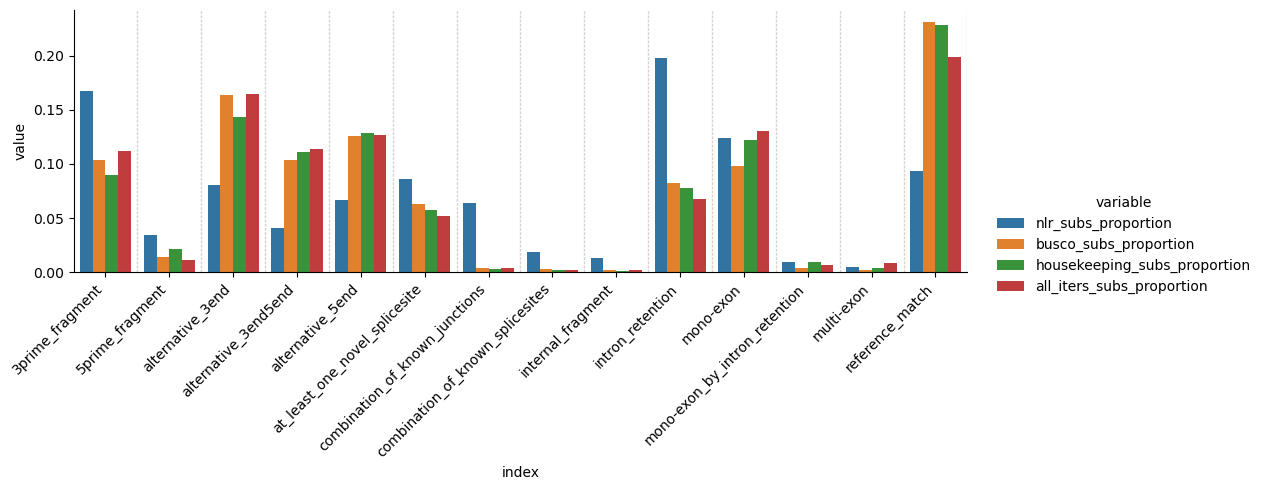

In [51]:
p01=sns.catplot(data=col0_1, x="index", y="value", hue="variable", kind="bar", aspect=2)
p01.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(plot1["index"].unique().tolist())):
    p01.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

## 2.1.2 at9900

In [52]:
at9900_1=plot1.loc[plot1["accession"] == "at9900"]

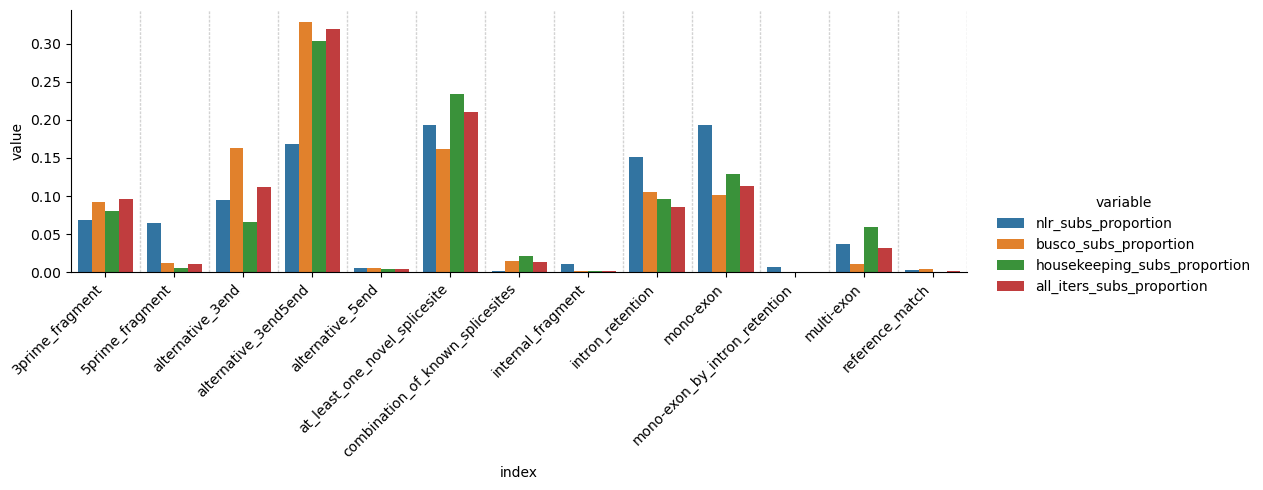

In [53]:
p01_2=sns.catplot(data=at9900_1, x="index", y="value", hue="variable", kind="bar", aspect=2)
p01_2.set_xticklabels(rotation=45, horizontalalignment='right')

for i in range(len(at9900_1["index"].unique().tolist())):
    p01_2.map(plt.axvline, x=i+0.5, color="lightgrey", dashes=(2, 1), zorder=0,linewidth=1)

## 2.2) Exon amount

In [45]:
sqanti_exons=tama_aug_exons[["index","accession","run","collapsing_tool","prediction_tool","nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"]]

In [46]:
plot2=sqanti_exons.melt(id_vars=["index","accession","run","collapsing_tool","prediction_tool"], value_vars=["nlr_exons","busco_iters_exons","house_iters_exons","all_iters_exons"])

### 2.2.1) Exon amount over all accessions

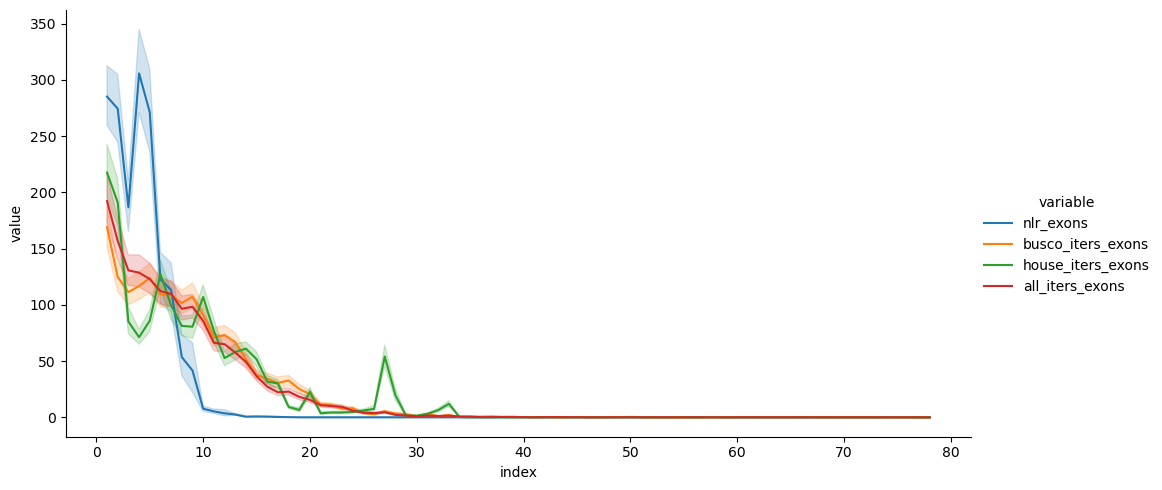

In [47]:
p2=sns.relplot(data=plot2, x="index", y="value", hue="variable", kind="line", aspect=2)

## 2.2.2) Col0 + at9900

In [61]:
ref_vs_9900=plot2.loc[(plot2["accession"] == "col0") | (plot2["accession"] == "at9900")]

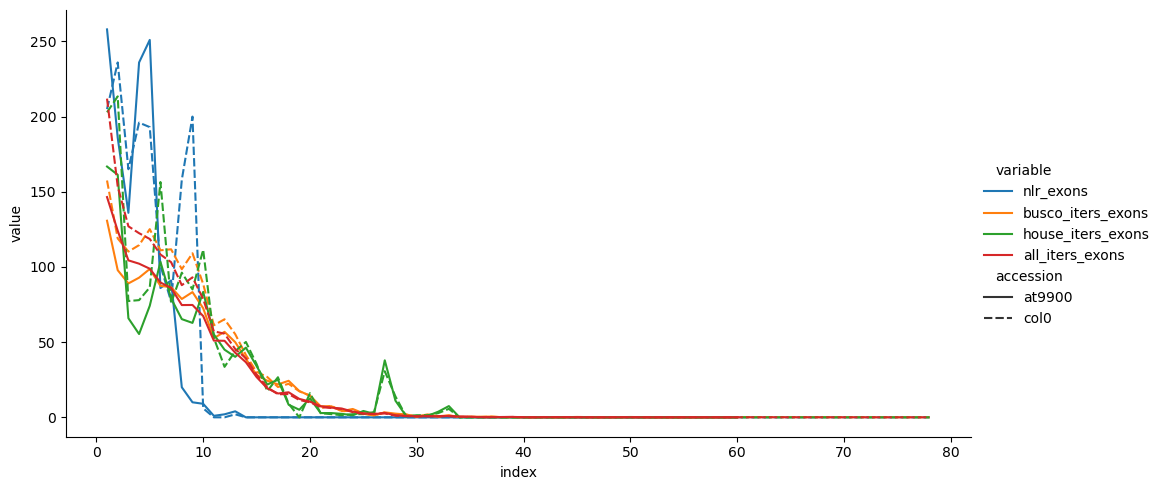

In [63]:
p3=sns.relplot(data=ref_vs_9900, x="index", y="value", hue="variable", kind="line", style="accession",aspect=2)

## 2.2.3) Col0

In [64]:
c0=plot2.loc[plot2["accession"] == "col0"]

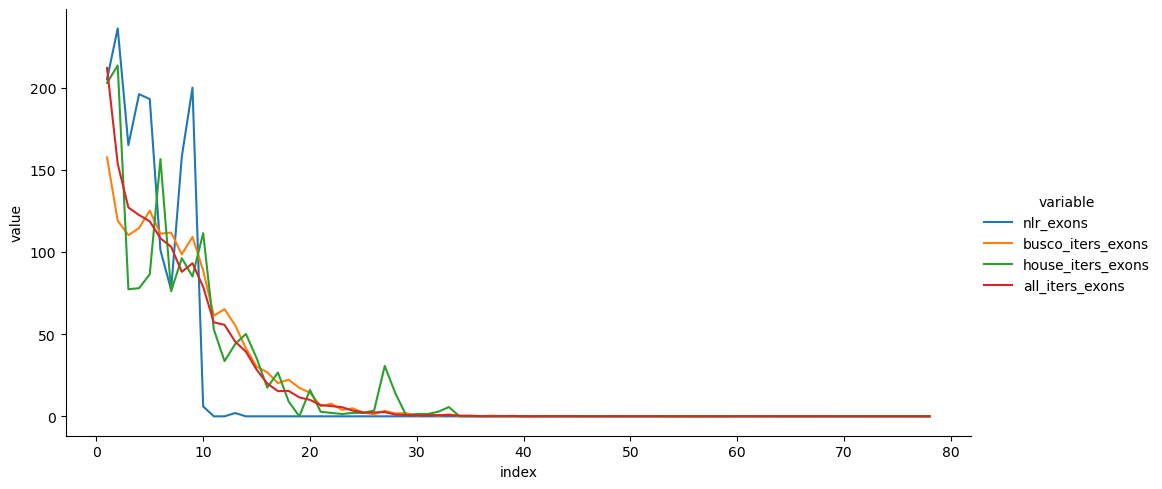

In [65]:
p3=sns.relplot(data=c0, x="index", y="value", hue="variable", kind="line",aspect=2)

## 2.2.4) at9900

In [66]:
at9900=plot2.loc[plot2["accession"] == "at9900"]

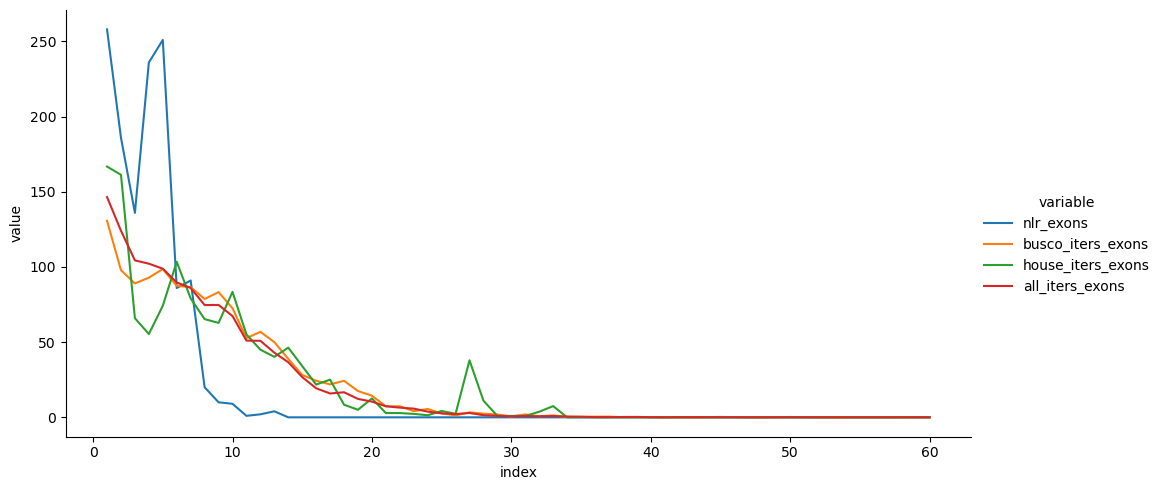

In [67]:
p4=sns.relplot(data=at9900, x="index", y="value", hue="variable", kind="line",aspect=2)

## 2.3) Length

In [68]:
sqanti_length=tama_aug_length[["index","accession","run","collapsing_tool","prediction_tool","nlr_length","busco_iters_length","house_iters_length","all_iters_length"]]

In [69]:
plot3=sqanti_length.melt(id_vars=["index","accession","run","collapsing_tool","prediction_tool"], value_vars=["nlr_length","busco_iters_length","house_iters_length","all_iters_length"])

### 2.3.1) Exon amount over all accessions

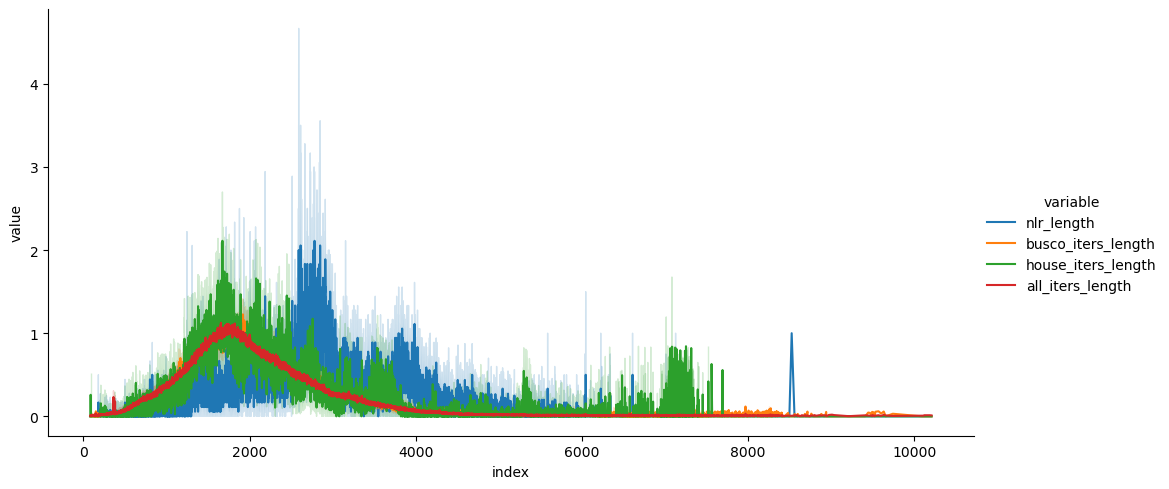

In [70]:
p3=sns.relplot(data=plot3, x="index", y="value", hue="variable", kind="line", aspect=2)

## 2.2.2) Col0 + at9900

In [71]:
ref_vs_9900=plot3.loc[(plot3["accession"] == "col0") | (plot3["accession"] == "at9900")]

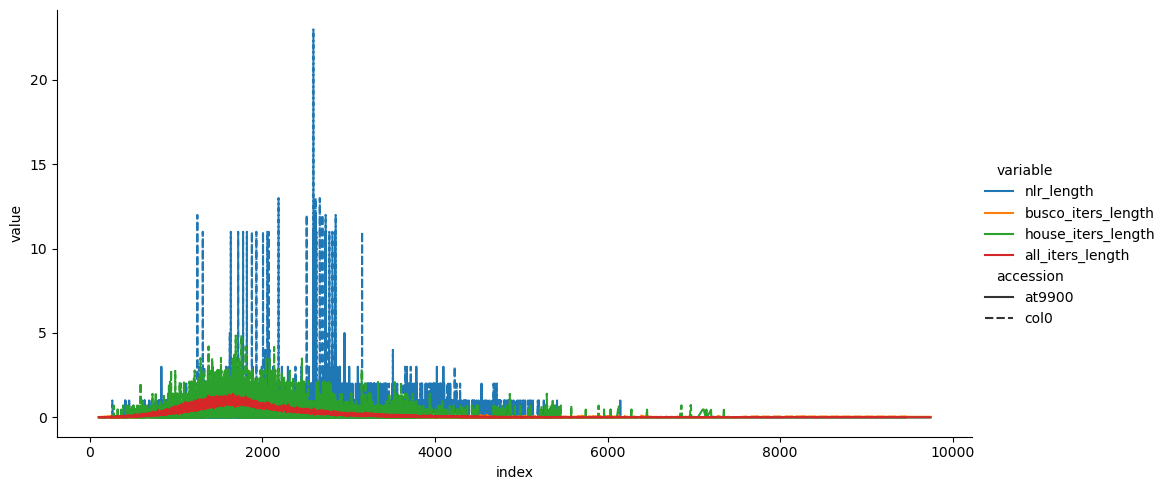

In [72]:
p3=sns.relplot(data=ref_vs_9900, x="index", y="value", hue="variable", kind="line", style="accession",aspect=2)

## 2.2.3) Col0

In [73]:
c0=plot3.loc[plot3["accession"] == "col0"]

IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

In [ ]:
p3=sns.relplot(data=c0, x="index", y="value", hue="variable", kind="line",aspect=2)

## 2.2.4) at9900

In [ ]:
at9900=plot3.loc[plot2["accession"] == "at9900"]

In [ ]:
p4=sns.relplot(data=at9900, x="index", y="value", hue="variable", kind="line",aspect=2)